# Exploratory Data Analysis: City Hotel (H2)

Covers the data-understanding requirements in section 6 of the project brief and prepares the generic preprocessing shared by the regression (`ADR`), classification (`IsCanceled`) and clustering tasks.

Nothing here changes the data on disk. Column definitions and timing come from the dataset paper (António, Almeida and Nunes, 2019).

## Key findings

| # | Pattern | Evidence | Generic preprocessing consequence |
|---|---|---|---|
| 1 | One third of rows are exact copies, and they are not random | 25,902 rows removed. Cancel rate falls from 41.7% to 30.0%. 93% of `Non Refund` rows disappear | Dedup before any split. Report results as dedup results |
| 2 | Random splits overstate performance | Cancellation AUC 0.901 on raw random split, 0.791 on dedup random, 0.747 on dedup chronological. ADR MAE 13.2 random, 22.2 chronological | Hold out the latest arrivals as the final test set |
| 3 | Prices drift upward quickly | Median ADR rose 13.4% from 2016 to 2017 on matching months | Keep a time signal and expect error to grow on later data |
| 4 | Several columns are recorded after the prediction point | `RequiredCarParkingSpaces` > 0 has a 0% cancel rate on 1,896 rows. Room changes have 5.2% vs 33.2% | Maintain per-task feature allowlists |
| 5 | `NULL` in `Agent` and `Company` means "not applicable" | Stated in the paper. `Agent` alone cuts ADR MAE by 2.4 | Keep them as flags plus grouped categories. Do not drop them for being NULL |
| 6 | True missing data is tiny | `Children` 4 rows, `Country` 24 rows | Simple constant fills. No model-based imputation needed |
| 7 | Most counts are zero-inflated | 7 of 8 sparse count features are at least 83% zeros | Binary flags or capping. IQR rules are not meaningful here |
| 8 | Text fields are padded | 7 columns are padded on every row, including numeric-looking ones | Strip before parsing, comparing or deduplicating |
| 9 | Date-derived week and weekday fields do not behave like the real calendar | Weekend nights match on 100% of rows only with a one-day offset | Use month and day-of-year. Treat weekday as a label only |
| 10 | Mass cancellations are batch events | Top 10 days hold 18.1% of cancellations | Do not read them as customer behavior. They explain much of the raw `Non Refund` signal |

Section 13 contains the full recommendations and the feature policy per task.

> **Test-set note.** The descriptive sections summarize all rows so that data-quality problems are not missed. The model probes in section 11 use only arrivals before 2017-06-03, leaving the latest 15% unused. Every learned step (imputation values, rare-level lists, scaling) must still be fitted on training data inside the pipeline.

## 1. Setup

In [2]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import PowerTransformer, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
DATA_SOURCE = "local"  # "local" or "drive", same convention as preprocessing.ipynb
LOCAL_DATA_PATH = Path("data/raw/H2.csv")
DRIVE_DATA_PATH = Path("/content/drive/MyDrive/hotel-booking-project/data/H2.csv")

if DATA_SOURCE == "drive":
    from google.colab import drive

    drive.mount("/content/drive")
    DATA_PATH = DRIVE_DATA_PATH
else:
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / LOCAL_DATA_PATH).is_file())
    DATA_PATH = root / LOCAL_DATA_PATH

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY = "#8a8985"
OUTCOME = {"Kept": BLUE, "Canceled": ORANGE}
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#a9cbef", BLUE, "#123f78"])
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f3f2ef", BLUE])

sns.set_theme(style="whitegrid", rc={
    "figure.figsize": (11, 4), "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#ececea", "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
pd.set_option("display.max_columns", 60, "display.max_rows", 120, "display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 2. Structure and data types

Everything is read as text, with `keep_default_na=False`, so that `NA` and `NULL` stay visible instead of being silently converted.

In [3]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns (spec: 79,330 and 31)")
raw.head(3).T.iloc[:12]

79,330 rows, 31 columns (spec: 79,330 and 31)


,0,1,2
IsCanceled,0,1,1
LeadTime,6,88,65
ArrivalDateYear,2015,2015,2015
ArrivalDateMonth,July,July,July
ArrivalDateWeekNumber,27,27,27
ArrivalDateDayOfMonth,1,1,1
StaysInWeekendNights,0,0,0
StaysInWeekNights,2,4,4
Adults,1,2,1
Children,0,0,0


In [4]:
stripped = raw.apply(lambda s: s.str.strip())
pd.DataFrame({
    "unique": raw.nunique(),
    "padded_rows": (raw != stripped).sum(),
    "NA": (stripped == "NA").sum(),
    "NULL": (stripped == "NULL").sum(),
    "Undefined": (stripped == "Undefined").sum(),
    "numeric_share": stripped.apply(lambda s: pd.to_numeric(s, errors="coerce").notna().mean()),
    "first_value": raw.iloc[0].map(repr),
})

,unique,padded_rows,NA,NULL,Undefined,numeric_share,first_value
IsCanceled,2,0,0,0,0,1.000,'0'
LeadTime,453,0,0,0,0,1.000,'6'
ArrivalDateYear,3,0,0,0,0,1.000,'2015'
ArrivalDateMonth,12,0,0,0,0,0.000,'July'
ArrivalDateWeekNumber,53,0,0,0,0,1.000,'27'
ArrivalDateDayOfMonth,31,0,0,0,0,1.000,'1'
StaysInWeekendNights,14,0,0,0,0,1.000,'0'
StaysInWeekNights,29,0,0,0,0,1.000,'2'
Adults,5,0,0,0,0,1.000,'1'
Children,5,0,4,0,0,1.000,'0'


**What this shows**

- The file matches the brief: 79,330 rows and 31 columns.
- `Meal`, `IsRepeatedGuest`, both room columns, `DepositType`, `Agent` and `Company` are padded on **every** row. Example: `'HB       '`. Unstripped comparisons fail silently.
- `Agent` and `Company` look numeric but are identifiers. Their numeric order has no meaning, so they must never be scaled or treated as quantities.
- `IsCanceled` and `IsRepeatedGuest` are categorical even though they contain digits.
- `ArrivalDateYear`, `ArrivalDateMonth` and `ArrivalDateDayOfMonth` combine into a real date, which all later time analysis uses.

In [5]:
NUMERIC = [
    "IsCanceled", "LeadTime", "ArrivalDateYear", "ArrivalDateWeekNumber", "ArrivalDateDayOfMonth",
    "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children", "Babies", "IsRepeatedGuest",
    "PreviousCancellations", "PreviousBookingsNotCanceled", "BookingChanges", "DaysInWaitingList",
    "ADR", "RequiredCarParkingSpaces", "TotalOfSpecialRequests",
]
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August",
          "September", "October", "November", "December"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def tidy(frame):
    """Exploration-only cleaning: strip padding, parse types, derive dates. Removes no rows."""
    out = frame.apply(lambda s: s.str.strip())
    out[NUMERIC] = out[NUMERIC].apply(pd.to_numeric, errors="coerce")
    out["ArrivalDate"] = pd.to_datetime(
        out["ArrivalDateYear"].astype(str) + "-" + out["ArrivalDateMonth"] + "-"
        + out["ArrivalDateDayOfMonth"].astype(str), format="%Y-%B-%d")
    out["StatusDate"] = pd.to_datetime(out["ReservationStatusDate"])
    out["BookingDate"] = out["ArrivalDate"] - pd.to_timedelta(out["LeadTime"], unit="D")
    out["TotalNights"] = out["StaysInWeekendNights"] + out["StaysInWeekNights"]
    out["TotalGuests"] = (out["Adults"] + out["Children"].fillna(0) + out["Babies"]).astype(int)
    out["Outcome"] = out["IsCanceled"].map({0: "Kept", 1: "Canceled"})
    return out


df = tidy(raw)
print("Arrival dates :", df.ArrivalDate.min().date(), "to", df.ArrivalDate.max().date())
print("Booking dates :", df.BookingDate.min().date(), "to", df.BookingDate.max().date())
print("Status dates  :", df.StatusDate.min().date(), "to", df.StatusDate.max().date())

Arrival dates : 2015-07-01 to 2017-08-31
Booking dates : 2014-10-17 to 2017-08-30
Status dates  : 2014-10-17 to 2017-09-07


### Data dictionary with timing

The paper states each observation is a snapshot from the **day before arrival**. Most fields can therefore have changed after the booking was made. "Mutable" below means the value may reflect events after booking.

| Column | Kind | When known | Note |
|---|---|---|---|
| `IsCanceled` | Binary target | Final | 1 covers `Canceled` and `No-Show` |
| `ADR` | Numeric target | Final | Lodging transactions divided by staying nights. Per room, not per guest |
| `LeadTime`, arrival date fields, `Meal`, `ReservedRoomType` | Numeric, temporal, categorical | Booking | Stays, party and meal can be amended |
| `StaysInWeekendNights`, `StaysInWeekNights`, `Adults`, `Children`, `Babies` | Counts | Booking, mutable | Captured the day before arrival |
| `MarketSegment`, `DistributionChannel`, `CustomerType` | Categorical | Booking | Commercial context |
| `Agent`, `Company` | ID | Booking | `NULL` means not applicable |
| `Country` | Categorical | Uncertain | Sourced from booking, change log and nationality tables, so timing is unclear |
| `IsRepeatedGuest`, `PreviousCancellations`, `PreviousBookingsNotCanceled` | History | Booking | Depends on a customer profile existing. Otherwise zero |
| `DepositType` | Categorical | Payment, mutable | Derived from payments before arrival or cancellation |
| `DaysInWaitingList` | Count | Confirmation | Known once the booking is confirmed |
| `TotalOfSpecialRequests`, `RequiredCarParkingSpaces` | Counts | Mutable | Can grow until arrival |
| `BookingChanges` | Count | Mutable | Counted until check-in or cancellation |
| `AssignedRoomType` | Categorical | Near arrival | Set by hotel operations |
| `ReservationStatus`, `ReservationStatusDate` | Outcome | Final | Restate the target |

## 3. Missing values and sentinels

The paper states that the PMS has no missing data as such, and that `NULL` in `Agent` or `Company` is a valid "not applicable" category.

In [6]:
absent = {
    "Children": df.Children.isna(), "Country": df.Country == "NULL", "Agent": df.Agent == "NULL",
    "Company": df.Company == "NULL", "MarketSegment": df.MarketSegment == "Undefined",
    "DistributionChannel": df.DistributionChannel == "Undefined",
}
meaning = ["missing", "undocumented", "not applicable (paper)", "not applicable (paper)", "unknown", "unknown"]
display(pd.DataFrame({
    "rows": {k: v.sum() for k, v in absent.items()},
    "share_%": {k: v.mean() * 100 for k, v in absent.items()},
    "cancel_rate_if_absent": {k: df.loc[v, "IsCanceled"].mean() for k, v in absent.items()},
    "cancel_rate_if_present": {k: df.loc[~v, "IsCanceled"].mean() for k, v in absent.items()},
    "meaning": dict(zip(absent, meaning)),
}))

channel = df.assign(HasAgent=df.Agent != "NULL", HasCompany=df.Company != "NULL")
display(channel.groupby(["HasAgent", "HasCompany"]).agg(
    bookings=("ADR", "size"), cancel_rate=("IsCanceled", "mean"), median_adr=("ADR", "median")))
display((pd.crosstab(channel.MarketSegment, channel.HasAgent, normalize="index") * 100).round(1)
        .rename(columns={False: "no agent %", True: "agent %"}))

,rows,share_%,cancel_rate_if_absent,cancel_rate_if_present,meaning
Children,4,0.005,1.000,0.417,missing
Country,24,0.030,0.917,0.417,undocumented
Agent,8131,10.250,0.321,0.428,not applicable (paper)
Company,75641,95.350,0.427,0.213,not applicable (paper)
MarketSegment,2,0.003,1.000,0.417,unknown
DistributionChannel,4,0.005,1.000,0.417,unknown


bookings  cancel_rate  median_adr
HasAgent HasCompany                                   
False    False           4489        0.407     100.000
         True            3642        0.215      79.000
True     False          71152        0.429     100.000
         True              47        0.043     100.750

HasAgent,no agent %,agent %
MarketSegment,,
Aviation,89.500,10.500
Complementary,90.200,9.800
Corporate,89.600,10.400
Direct,40.000,60.000
Groups,13.600,86.400
Offline TA/TO,1.300,98.700
Online TA,0.500,99.500
Undefined,100.000,0.000


**What this shows**

- True gaps are negligible: `Children` has 4 rows, `Country` 24, and `Undefined` appears in 2 and 4 rows. Their cancel rates look extreme only because the groups are tiny.
- `Agent` and `Company` are informative. Bookings with a company cancel at 21.3% against 42.7% without one. Having an agent is nearly equivalent to arriving through a travel-agent segment (99.5% for `Online TA`).
- The agent and company fields are nearly mutually exclusive: only 47 raw rows have both.

**Consequence:** `NULL` here is a business signal. Encode `HasAgent` and `HasCompany`, keep top levels, and do not impute. Fill `Children` with 0, the overwhelming mode, and set `Country` `NULL` to `Unknown`.

## 4. Duplicates

The data has no booking ID, so identical rows could be separate rooms in one block or repeated records. They cannot be told apart from the file alone.

In [7]:
dup_any = raw.duplicated(keep=False)
group_id = raw.groupby(list(raw.columns), sort=False).ngroup()
block_size = group_id.map(group_id.value_counts())
dd = df[~raw.duplicated()].copy()
without_ids = len(raw.drop(columns=["Agent", "Company"]).drop_duplicates())
print(f"Exact duplicates to remove     : {raw.duplicated().sum():,} ({raw.duplicated().mean():.1%})")
print(f"Rows involved in any duplicate : {dup_any.sum():,} ({dup_any.mean():.1%})")
print(f"Rows after dedup               : {len(dd):,}")
print(f"Largest identical block        : {block_size.max()} rows")
print(f"Dedup after dropping Agent and Company leaves {without_ids:,}, losing {len(dd) - without_ids} distinct bookings")


def compare(col):
    return pd.DataFrame({
        "raw_share_%": df[col].value_counts(normalize=True) * 100,
        "dedup_share_%": dd[col].value_counts(normalize=True) * 100,
        "raw_cancel": df.groupby(col).IsCanceled.mean(),
        "dedup_cancel": dd.groupby(col).IsCanceled.mean(),
        "rows_removed_%": (1 - dd[col].value_counts() / df[col].value_counts()) * 100,
    }).sort_values("raw_share_%", ascending=False)


print(f"\nCancel rate raw {df.IsCanceled.mean():.1%} -> dedup {dd.IsCanceled.mean():.1%}; "
      f"mean ADR {df.ADR.mean():.1f} -> {dd.ADR.mean():.1f}; median lead {df.LeadTime.median():.0f} -> {dd.LeadTime.median():.0f}")
display(compare("DepositType"), compare("MarketSegment"))

Exact duplicates to remove     : 25,902 (32.7%)
Rows involved in any duplicate : 31,748 (40.0%)
Rows after dedup               : 53,428
Largest identical block        : 180 rows
Dedup after dropping Agent and Company leaves 53,414, losing 14 distinct bookings

Cancel rate raw 41.7% -> dedup 30.0%; mean ADR 105.3 -> 111.0; median lead 74 -> 50


,raw_share_%,dedup_share_%,raw_cancel,dedup_cancel,rows_removed_%
DepositType,,,,,
No Deposit,83.754,98.390,0.305,0.289,20.881
Non Refund,16.221,1.582,0.998,0.972,93.433
Refundable,0.025,0.028,0.700,0.667,25.000


,raw_share_%,dedup_share_%,raw_cancel,dedup_cancel,rows_removed_%
MarketSegment,,,,,
Online TA,48.844,65.497,0.374,0.361,9.688
Offline TA/TO,21.111,13.609,0.428,0.173,56.583
Groups,17.616,4.932,0.689,0.338,81.145
Direct,7.681,10.405,0.173,0.164,8.764
Corporate,3.764,4.168,0.215,0.119,25.419
Complementary,0.683,0.960,0.118,0.111,5.351
Aviation,0.299,0.425,0.219,0.198,4.219
Undefined,0.003,0.004,1.000,1.000,0.000


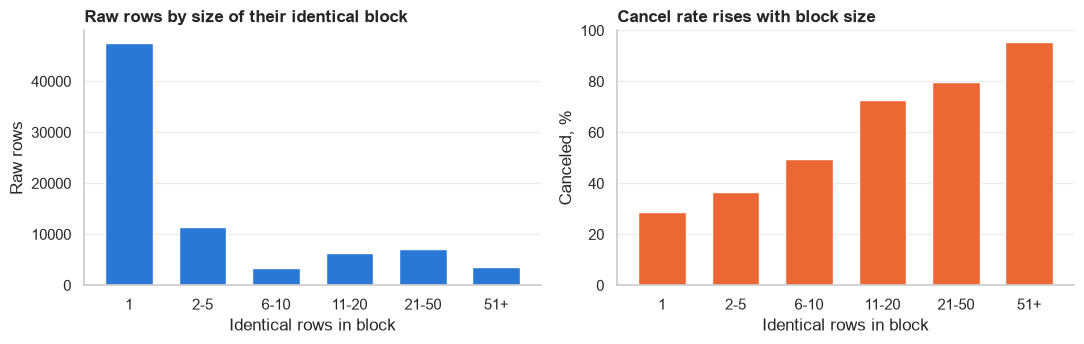

In [8]:
labels = ["1", "2-5", "6-10", "11-20", "21-50", "51+"]
bucket = pd.cut(block_size, bins=[0, 1, 5, 10, 20, 50, 200], labels=labels)
by_block = df.groupby(bucket, observed=True).IsCanceled.agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(labels, by_block["size"], color=BLUE, width=.65)
axes[0].set(title="Raw rows by size of their identical block", xlabel="Identical rows in block", ylabel="Raw rows")
axes[1].bar(labels, by_block["mean"] * 100, color=ORANGE, width=.65)
axes[1].set(title="Cancel rate rises with block size", xlabel="Identical rows in block", ylabel="Canceled, %", ylim=(0, 100))
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()

**What this shows**

- 40% of rows belong to an identical block, and the biggest block has 180 rows.
- Duplication is concentrated: 93.4% of `Non Refund` rows and 81.1% of `Groups` rows are removed, against 8.8% for `Direct`.
- Removing them changes the task. Cancel rate drops from 41.7% to 30.0%, and `Offline TA/TO` drops from 42.8% to 17.3%.
- Blocks are probably real group inventory: they share status dates and are often canceled together.

**Decision:** dedup on all 31 columns, after stripping and **before** dropping any column. Removing `Agent` and `Company` first merges 14 distinct bookings. Dedup is justified mainly because twins would otherwise span train and test (section 11), and because one group decision would be counted many times. The team should state in the report that the results describe distinct booking patterns, not room-level volume.

All sections below use the deduplicated data (`dd`) unless they say otherwise.

## 5. Logical consistency

Checks that follow from the meaning of the columns.

In [9]:
co = df.ReservationStatus == "Check-Out"
gap = (df.StatusDate - df.ArrivalDate).dt.days
history = df.PreviousCancellations + df.PreviousBookingsNotCanceled
rules = {
    "IsCanceled=1 differs from status not Check-Out": (df.IsCanceled == 1) != (df.ReservationStatus != "Check-Out"),
    "Check-Out date differs from arrival + nights": co & (gap != df.TotalNights),
    "Canceled after arrival date": (df.ReservationStatus == "Canceled") & (gap > 0),
    "Canceled before booking date": (df.ReservationStatus == "Canceled") & (df.StatusDate < df.BookingDate),
    "No-Show date differs from arrival": (df.ReservationStatus == "No-Show") & (gap != 0),
    "Zero guests": df.TotalGuests == 0,
    "Zero adults, children present": (df.Adults == 0) & (df.TotalGuests > 0),
    "Zero nights": df.TotalNights == 0,
    "ADR = 0": df.ADR == 0,
    "ADR > 0 with zero nights": (df.ADR > 0) & (df.TotalNights == 0),
    "ADR > 500": df.ADR > 500,
    "Babies >= 3": df.Babies >= 3,
    "Repeat guest with no history": (df.IsRepeatedGuest == 1) & (history == 0),
    "History present, not flagged repeat": (df.IsRepeatedGuest == 0) & (history > 0),
    "Complementary segment with ADR > 0": (df.MarketSegment == "Complementary") & (df.ADR > 0),
}
pd.DataFrame({
    "rows": {k: v.sum() for k, v in rules.items()},
    "share_%": {k: v.mean() * 100 for k, v in rules.items()},
    "cancel_rate": {k: df.loc[v, "IsCanceled"].mean() if v.any() else np.nan for k, v in rules.items()},
    "median_adr": {k: df.loc[v, "ADR"].median() if v.any() else np.nan for k, v in rules.items()},
})

,rows,share_%,cancel_rate,median_adr
IsCanceled=1 differs from status not Check-Out,0,0.000,NaN,NaN
Check-Out date differs from arrival + nights,6,0.008,0.000,185.000
Canceled after arrival date,0,0.000,NaN,NaN
Canceled before booking date,0,0.000,NaN,NaN
No-Show date differs from arrival,0,0.000,NaN,NaN
Zero guests,167,0.211,0.138,0.000
"Zero adults, children present",223,0.281,0.377,88.770
Zero nights,331,0.417,0.069,0.000
ADR = 0,1208,1.523,0.107,0.000
ADR > 0 with zero nights,0,0.000,NaN,NaN


**What this shows**

- The lifecycle fields are very clean. `IsCanceled` matches status exactly, and nearly every check-out date equals arrival plus nights (6 exceptions). This also confirms `No-Show` counts as canceled.
- Zero guests (167 rows) has no valid meaning, so those rows should be dropped.
- Zero adults with children (223 rows) is unusual but plausible for bookings with a guardian on another reservation, so keep them.
- Zero nights (331 rows) always has `ADR = 0`. ADR is undefined for them, since the formula divides by nights.
- 4,806 rows have history but no repeat flag, and they cancel at 96.7%. Both fields are built from customer profiles, so this signals a batch effect (section 9), not a customer trait.

In [10]:
display(df.nlargest(4, "ADR")[["ADR", "ReservedRoomType", "Adults", "TotalNights", "DepositType", "MarketSegment", "LeadTime", "ReservationStatus"]])
display(df[df.ADR == 0].groupby("MarketSegment").agg(
    bookings=("ADR", "size"), zero_night=("TotalNights", lambda s: (s == 0).mean()), cancel=("IsCanceled", "mean")
).sort_values("bookings", ascending=False))
print("Portugal share of zero-ADR rows:", f"{(df[df.ADR == 0].Country == 'PRT').mean():.1%}")
display(df.loc[df.Babies >= 3, ["Adults", "Children", "Babies", "ADR", "TotalNights", "ReservedRoomType"]])

,ADR,ReservedRoomType,Adults,TotalNights,DepositType,MarketSegment,LeadTime,ReservationStatus
8455,"5,400.000",A,2,1,Non Refund,Offline TA/TO,35,Canceled
71343,510.000,A,1,1,No Deposit,Offline TA/TO,0,Check-Out
63852,451.500,E,2,2,No Deposit,Direct,81,Check-Out
63729,375.500,D,3,2,No Deposit,Online TA,21,Check-Out


,bookings,zero_night,cancel
MarketSegment,,,
Complementary,508,0.045,0.120
Offline TA/TO,236,0.352,0.114
Online TA,173,0.780,0.081
Groups,144,0.056,0.097
Direct,111,0.532,0.081
Corporate,30,0.567,0.100
Aviation,6,1.000,0.167


Portugal share of zero-ADR rows: 82.4%


,Adults,Children,Babies,ADR,TotalNights,ReservedRoomType
6559,2,0.000,10,84.450,2,D
38596,1,0.000,9,95.000,3,A


**What this shows**

- `ADR = 5400` is a clear error: a one-night, `Non Refund`, canceled, `A` room stay. The next value is 510, which is high but plausible.
- Zero ADR has two sources: `Complementary` stays (508 rows, intentionally free) and zero-night rows. These are a different pricing regime. Excluding them from ADR training is cleaner than treating them as low prices.
- The 9 and 10 `Babies` values are likely data-entry errors, but with two rows the effect is negligible. A cap at 2 handles them.

### Calendar checks

In [11]:
def weekend_nights(frame, shift):
    start = frame.ArrivalDate.dt.weekday.to_numpy()
    nights = frame.TotalNights.to_numpy()
    total = np.zeros(len(frame), dtype=int)
    for i in range(int(nights.max())):
        total += (i < nights) & np.isin((start + i + shift) % 7, [5, 6])
    return total


match = pd.Series({s: (weekend_nights(df, s) == df.StaysInWeekendNights).mean() * 100 for s in range(-3, 4)}, name="rows matching, %")
match.index.name = "days added to arrival date"
display(match.to_frame().T)

display(df[df.TotalNights.between(1, 2)].assign(Day=lambda t: t.ArrivalDate.dt.day_name())
        .pivot_table(index="Day", columns="TotalNights", values="StaysInWeekendNights").reindex(WEEKDAYS)
        .rename(columns=lambda n: f"{n}-night stay"))

iso = df.ArrivalDate.dt.isocalendar().week.astype(int)
display(pd.crosstab(df.ArrivalDateYear, (iso - df.ArrivalDateWeekNumber).clip(-3, 3)).rename_axis(columns="ISO week minus source week"))
steps = df.drop_duplicates("ArrivalDate").sort_values("ArrivalDate")
print("Weekday on which the source week number advances:",
      steps.loc[steps.ArrivalDateWeekNumber.diff().fillna(0) != 0, "ArrivalDate"].dt.day_name().value_counts().to_dict())

days added to arrival date,-3,-2,-1,0,1,2,3
"rows matching, %",38.051,55.147,100.000,47.618,29.858,24.327,26.457


TotalNights,1-night stay,2-night stay
Day,,
Monday,1.000,1.000
Tuesday,0.000,0.000
Wednesday,0.000,0.000
Thursday,0.000,0.000
Friday,0.000,0.000
Saturday,0.000,1.000
Sunday,1.000,2.000


ISO week minus source week,-2,-1,0,3
ArrivalDateYear,,,,
2015,0,1055,12627,0
2016,4609,33353,0,178
2017,0,3391,24014,103


Weekday on which the source week number advances: {'Sunday': 113, 'Friday': 1}


**What this shows**

- Weekend-night counts match the real calendar on only 47.6% of rows, yet they match on **exactly 100%** if the arrival date is moved back one day. The offset is perfectly systematic. On one- and two-night stays, a Monday arrival always counts one weekend night, and a Friday arrival counts none.
- `ArrivalDateWeekNumber` is not an ISO week. It advances on Sundays and differs from ISO by a year-specific offset.
- The cause cannot be determined from the file, and the paper does not explain it.

**Consequence:** Do not engineer "arrives on a weekend" from the calendar date. Weekday can be used as a categorical label because the shift is constant. Prefer `ArrivalDateMonth` or day of year over the source week number.

## 6. Distributions, skew and outliers

In [12]:
COUNTS = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights", "TotalNights", "Adults", "Children", "Babies",
          "PreviousCancellations", "PreviousBookingsNotCanceled", "BookingChanges", "DaysInWaitingList",
          "ADR", "RequiredCarParkingSpaces", "TotalOfSpecialRequests"]


def outlier_table(frame, cols):
    rows = {}
    for c in cols:
        s = frame[c].dropna()
        q1, q3 = s.quantile([.25, .75])
        fence = q3 + 1.5 * (q3 - q1)
        rows[c] = {"min": s.min(), "median": s.median(), "p99": s.quantile(.99), "max": s.max(), "skew": s.skew(),
                   "kurtosis": s.kurt(), "zero_%": (s == 0).mean() * 100, "IQR_flagged_%": (s > fence).mean() * 100,
                   "|z|>3_%": (np.abs(stats.zscore(s)) > 3).mean() * 100}
    return pd.DataFrame(rows).T.sort_values("skew", ascending=False)


outlier_table(dd, COUNTS)

,min,median,p99,max,skew,kurtosis,zero_%,IQR_flagged_%,|z|>3_%
Babies,0.000,0.000,0.000,10.000,36.768,"2,854.002",99.309,0.691,0.691
ADR,0.000,105.300,235.000,"5,400.000",25.375,"2,745.138",2.016,2.476,0.515
PreviousCancellations,0.000,0.000,1.000,21.000,22.876,713.643,97.795,2.205,0.397
PreviousBookingsNotCanceled,0.000,0.000,5.000,72.000,19.336,482.064,97.134,2.866,0.816
DaysInWaitingList,0.000,0.000,33.000,391.000,17.285,375.652,98.656,1.344,0.956
BookingChanges,0.000,0.000,3.000,21.000,6.516,94.784,83.447,16.553,1.409
RequiredCarParkingSpaces,0.000,0.000,1.000,3.000,5.124,25.546,96.451,3.549,3.549
TotalNights,0.000,3.000,10.000,57.000,3.757,41.410,0.539,2.216,1.159
Children,0.000,0.000,2.000,3.000,3.492,11.608,90.759,9.241,3.835
StaysInWeekNights,0.000,2.000,7.000,41.000,2.949,29.787,7.107,1.286,0.925


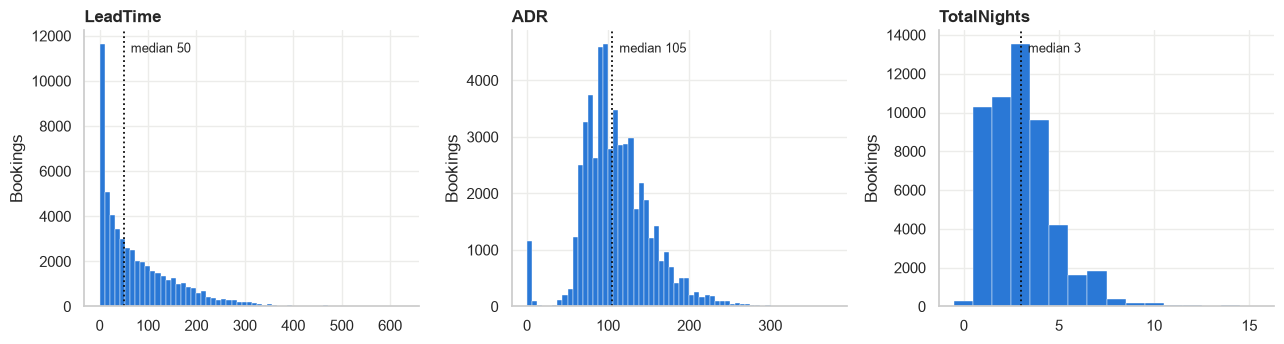

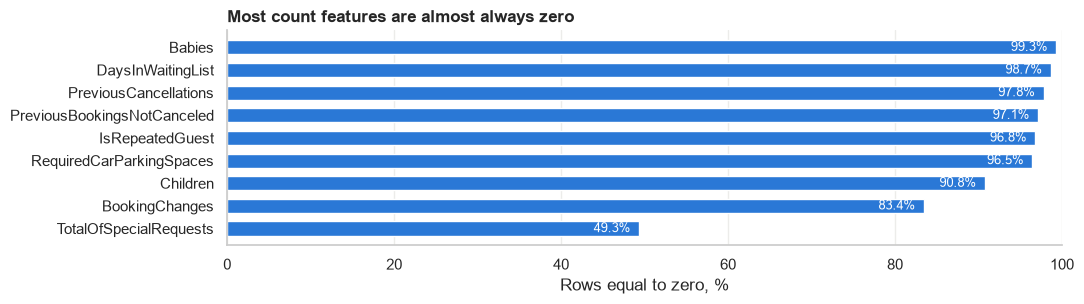

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, limit) in zip(axes, [("LeadTime", 700), ("ADR", 400), ("TotalNights", 15)]):
    s = dd.loc[dd[col] <= limit, col]
    bins = np.arange(-.5, limit + 1) if col == "TotalNights" else 60
    ax.hist(s, bins=bins, color=BLUE, edgecolor="white", linewidth=.3)
    ax.axvline(s.median(), color="#0b0b0b", linestyle=":", linewidth=1.3)
    ax.annotate(f"median {s.median():.0f}", (s.median(), ax.get_ylim()[1] * .92), xytext=(5, 0), textcoords="offset points", fontsize=9)
    ax.set(title=col, xlabel="", ylabel="Bookings")
plt.tight_layout()

sparse = ["Children", "Babies", "PreviousCancellations", "PreviousBookingsNotCanceled", "BookingChanges",
          "DaysInWaitingList", "RequiredCarParkingSpaces", "TotalOfSpecialRequests", "IsRepeatedGuest"]
zero_share = (dd[sparse] == 0).mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.barh(zero_share.index, zero_share, color=BLUE, height=.62)
for y, v in enumerate(zero_share):
    ax.text(v - 1, y, f"{v:.1f}%", va="center", ha="right", color="white", fontsize=9)
ax.set(title="Most count features are almost always zero", xlabel="Rows equal to zero, %", xlim=(0, 100))
ax.grid(axis="y", visible=False)
plt.tight_layout()

**What this shows**

- Seven count features have 83% or more zeros. The IQR is often 0, so IQR and z-score rules just flag every non-zero row. `BookingChanges` would be 16.6% "outliers", `Adults` 8.6%.
- Long tails are real behavior for `LeadTime`, stays and history, so they should be transformed or capped and not deleted.
- `ADR` skew of 25 comes from one row. It falls to 0.64 once that row is removed.

,raw,sqrt,log1p,yeo_johnson
skewness after transform,,,,
LeadTime,1.576,0.370,-0.778,-0.124
TotalNights,3.757,0.738,0.132,-0.003
StaysInWeekNights,2.949,-0.321,-0.298,0.018
StaysInWeekendNights,1.197,0.012,0.145,0.059
ADR,0.641,-1.426,-4.690,0.177
"ADR, paid rows only",1.078,0.326,-1.326,0.111


Whole-number ADR share: 47.0%
Most common ADR values, % of rows: {0.0: 2.02, 75.0: 1.87, 65.0: 1.81, 95.0: 1.32, 90.0: 1.17, 99.0: 1.16}


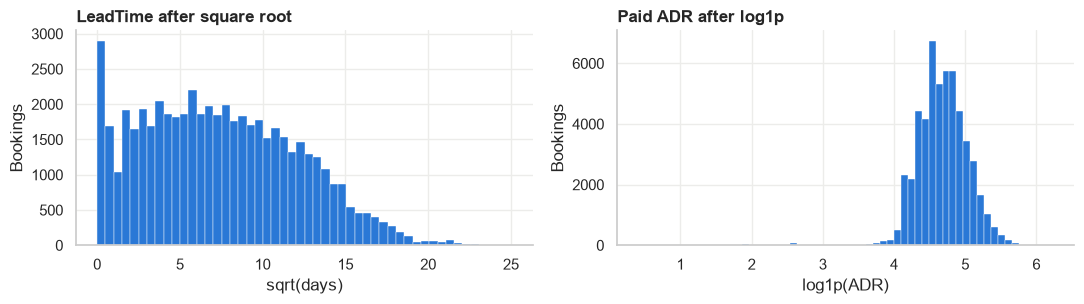

In [14]:
def skews(s):
    s = s.astype(float)
    return {"raw": s.skew(), "sqrt": np.sqrt(s).skew(), "log1p": np.log1p(s).skew(),
            "yeo_johnson": pd.Series(PowerTransformer().fit_transform(s.to_frame()).ravel()).skew()}


capped = dd[dd.ADR <= 1000]
adr_paid = dd.loc[dd.ADR.between(.01, 1000), "ADR"]
table = {c: skews(capped[c]) for c in ["LeadTime", "TotalNights", "StaysInWeekNights", "StaysInWeekendNights", "ADR"]}
table["ADR, paid rows only"] = skews(adr_paid)
display(pd.DataFrame(table).T.rename_axis("skewness after transform"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(np.sqrt(dd.LeadTime), bins=50, color=BLUE, edgecolor="white", linewidth=.3)
axes[0].set(title="LeadTime after square root", xlabel="sqrt(days)", ylabel="Bookings")
axes[1].hist(np.log1p(adr_paid), bins=60, color=BLUE, edgecolor="white", linewidth=.3)
axes[1].set(title="Paid ADR after log1p", xlabel="log1p(ADR)", ylabel="Bookings")
plt.tight_layout()

print("Whole-number ADR share:", f"{(dd.ADR % 1 == 0).mean():.1%}")
print("Most common ADR values, % of rows:", (dd.ADR.value_counts(normalize=True).head(6) * 100).round(2).to_dict())

**What this shows**

- `LeadTime`: square root or Yeo-Johnson works well. `log1p` overshoots to negative skew.
- `TotalNights` and the stay counts: `log1p` or Yeo-Johnson are close to symmetric.
- Paid ADR: square root or Yeo-Johnson. Zero ADR rows distort any log transform, which supports excluding them from regression.
- ADR is **sticky at price points** (47.0% whole numbers), so residuals will be lumpy.

Tree models do not need these transforms. Linear models, KNN, SVM, MLP, PCA and K-Means do.

## 7. Categorical structure

,levels,top,top_%,levels_under_1%,rows_in_those_%,levels_under_30_rows
column,,,,,,
ArrivalDateMonth,12,August,12.336,0,0.000,0
Meal,4,BB,77.167,1,0.021,1
Country,167,PRT,24.734,152,12.984,109
MarketSegment,8,Online TA,65.497,3,1.389,1
DistributionChannel,5,TA/TO,83.381,2,0.346,1
ReservedRoomType,8,A,71.015,3,0.930,2
AssignedRoomType,9,A,62.523,3,0.825,1
DepositType,3,No Deposit,98.390,1,0.028,1
CustomerType,4,Transient,83.554,1,0.507,0


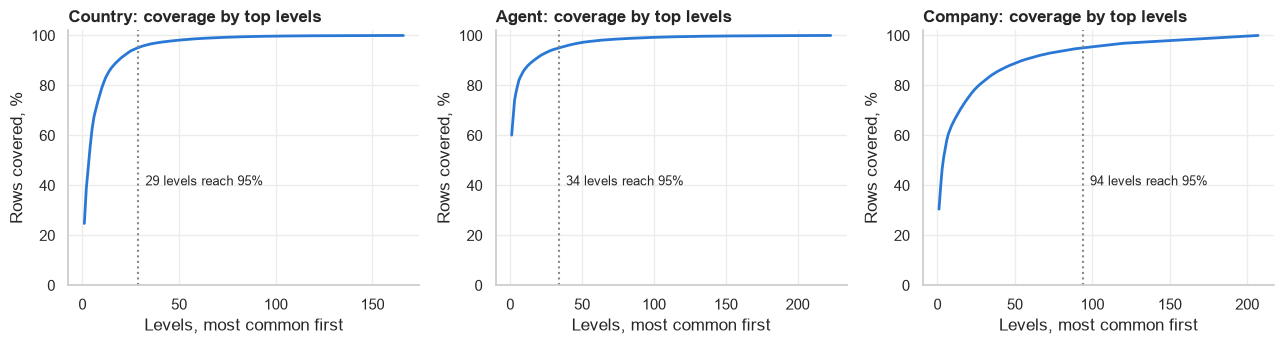

In [15]:
CATS = ["ArrivalDateMonth", "Meal", "Country", "MarketSegment", "DistributionChannel", "ReservedRoomType",
        "AssignedRoomType", "DepositType", "CustomerType", "Agent", "Company"]
card = []
for c in CATS:
    share = dd[c].value_counts(normalize=True)
    card.append({"column": c, "levels": len(share), "top": share.index[0], "top_%": share.iloc[0] * 100,
                 "levels_under_1%": (share < .01).sum(), "rows_in_those_%": share[share < .01].sum() * 100,
                 "levels_under_30_rows": (dd[c].value_counts() < 30).sum()})
display(pd.DataFrame(card).set_index("column"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Country", "Agent", "Company"]):
    share = dd.loc[dd[col] != "NULL", col].value_counts(normalize=True).cumsum().to_numpy() * 100
    ax.plot(range(1, len(share) + 1), share, color=BLUE, linewidth=2)
    k = int(np.searchsorted(share, 95)) + 1
    ax.axvline(k, color=GRAY, linestyle=":")
    ax.annotate(f"{k} levels reach 95%", (k, 40), xytext=(5, 0), textcoords="offset points", fontsize=9)
    ax.set(title=f"{col}: coverage by top levels", xlabel="Levels, most common first", ylabel="Rows covered, %", ylim=(0, 102))
plt.tight_layout()

**What this shows**

- `Country`, `Agent` and `Company` are high-cardinality with long tails. One-hot encoding them whole would add about 600 sparse columns.
- Grouping is efficient: see the 95% coverage lines above.
- `Agent` 9 alone covers 53.8% of rows, so `Agent` is partly a proxy for a single channel.
- Near-empty levels (`Meal = FB`, room `C` and `P`, `Refundable`, `Undefined`) need rare-level grouping fitted on training data.

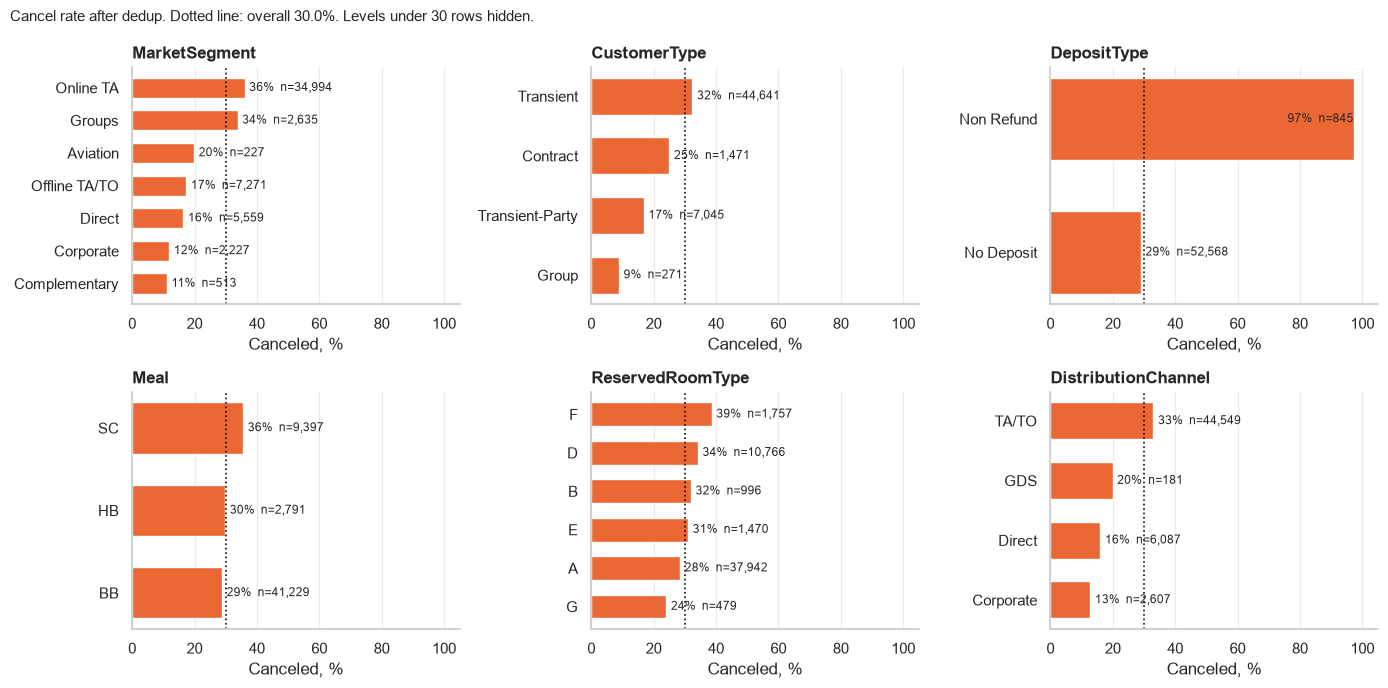

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
overall = dd.IsCanceled.mean() * 100
for ax, col in zip(axes.ravel(), ["MarketSegment", "CustomerType", "DepositType", "Meal", "ReservedRoomType", "DistributionChannel"]):
    t = dd.groupby(col).IsCanceled.agg(["mean", "size"]).query("size >= 30").sort_values("mean")
    ax.barh(t.index, t["mean"] * 100, color=ORANGE, height=.62)
    ax.axvline(overall, color="#0b0b0b", linestyle=":", linewidth=1.2)
    for y, (v, n) in enumerate(zip(t["mean"] * 100, t["size"])):
        ax.text(min(v + 1.5, 76), y, f"{v:.0f}%  n={n:,}", va="center", fontsize=8.5)
    ax.set(title=col, xlim=(0, 105), xlabel="Canceled, %")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Cancel rate after dedup. Dotted line: overall {overall:.1f}%. Levels under 30 rows hidden.", x=.01, ha="left", fontsize=11)
plt.tight_layout()

In [17]:
top = dd.Country.value_counts().head(10).index
display(pd.DataFrame({
    "bookings": dd.Country.value_counts().loc[top],
    "raw_cancel": df.groupby("Country").IsCanceled.mean().loc[top],
    "dedup_cancel": dd.groupby("Country").IsCanceled.mean().loc[top],
    "median_adr": dd.groupby("Country").ADR.median().loc[top],
    "median_lead": dd.groupby("Country").LeadTime.median().loc[top],
}))
print("Portugal share by final status, %:", (pd.crosstab(dd.ReservationStatus, dd.Country == "PRT", normalize="index")[True] * 100).round(1).to_dict())

,bookings,raw_cancel,dedup_cancel,median_adr,median_lead
Country,,,,,
PRT,13215,0.649,0.370,90.000,24.000
FRA,7412,0.196,0.209,108.000,53.000
GBR,4528,0.294,0.287,109.800,75.000
DEU,4467,0.176,0.208,105.300,83.000
ESP,3784,0.288,0.295,113.000,34.000
ITA,2647,0.379,0.379,110.000,66.000
BEL,1690,0.219,0.217,116.100,75.000
BRA,1589,0.406,0.400,107.700,56.000
NLD,1431,0.208,0.209,110.000,58.000


Portugal share by final status, %: {'Canceled': 29.3, 'Check-Out': 22.3, 'No-Show': 53.1}


**What this shows**

- `Online TA` has the highest cancel rate of the main segments (36.1%), which reverses the raw picture, where `Groups` looked worst at 68.9%. This reversal is entirely due to duplicates.
- `DepositType = Non Refund` still cancels at 97.2%, a result that contradicts common sense. It now covers only 1.6% of rows.
- After dedup, Portugal cancels at 37.0% rather than 64.9%, but it is still above most other major markets. Portugal also makes up 53.1% of `No-Show` rows against 22.3% of check-outs. The difference could reflect local behavior or a default value that is only corrected at check-in. The file cannot settle which, so it is a leakage risk.

## 8. The two targets

,count,mean,std,min,25%,50%,75%,max
Outcome,,,,,,,,
Canceled,"16,049.000",117.300,58.400,0.000,89.100,110.500,139.200,"5,400.000"
Kept,"37,379.000",108.300,42.600,0.000,80.800,102.000,130.500,510.000


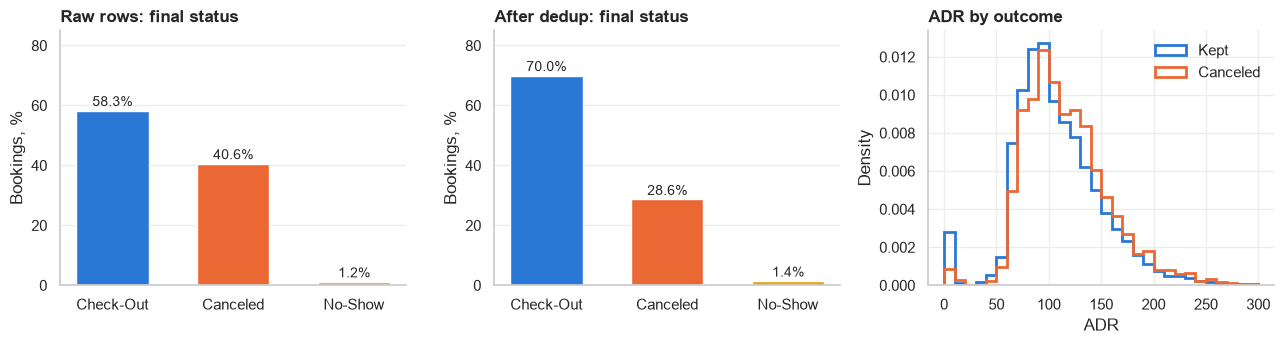

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, frame) in zip(axes[:2], [("Raw rows", df), ("After dedup", dd)]):
    share = frame.ReservationStatus.value_counts(normalize=True).reindex(["Check-Out", "Canceled", "No-Show"]) * 100
    ax.bar(share.index, share, color=[BLUE, ORANGE, YELLOW], width=.6)
    for x, v in enumerate(share):
        ax.text(x, v + 1.5, f"{v:.1f}%", ha="center", fontsize=10)
    ax.set(title=f"{title}: final status", ylabel="Bookings, %", ylim=(0, 85))
    ax.grid(axis="x", visible=False)
for label, color in OUTCOME.items():
    axes[2].hist(dd.loc[(dd.Outcome == label) & (dd.ADR <= 300), "ADR"], bins=np.arange(0, 301, 10), density=True,
                 histtype="step", linewidth=2, color=color, label=label)
axes[2].set(title="ADR by outcome", xlabel="ADR", ylabel="Density")
axes[2].legend(frameon=False)
plt.tight_layout()
dd.groupby("Outcome").ADR.describe().round(1)

**Cancellation.** The dedup split is about 70/30: moderately imbalanced, so accuracy alone will flatter a model. Use stratified folds, and report F1 and PR-AUC. No resampling is needed at this level. Canceled bookings have slightly higher ADR, a median of 110.5 against 102.0.

TotalGuests,1,2,3,4
ReservedRoomType,,,,
A,88.000,97.000,122.000,129.000
B,98.000,87.000,95.000,140.000
C,104.000,110.000,NaN,74.000
D,113.000,124.000,151.000,142.000
E,141.000,154.000,185.000,177.000
F,191.000,183.000,186.000,191.000
G,238.000,216.000,213.000,228.000


Spearman: ADR vs guests 0.42, ADR per guest vs guests -0.51, ADR vs nights -0.00, ADR vs lead -0.01


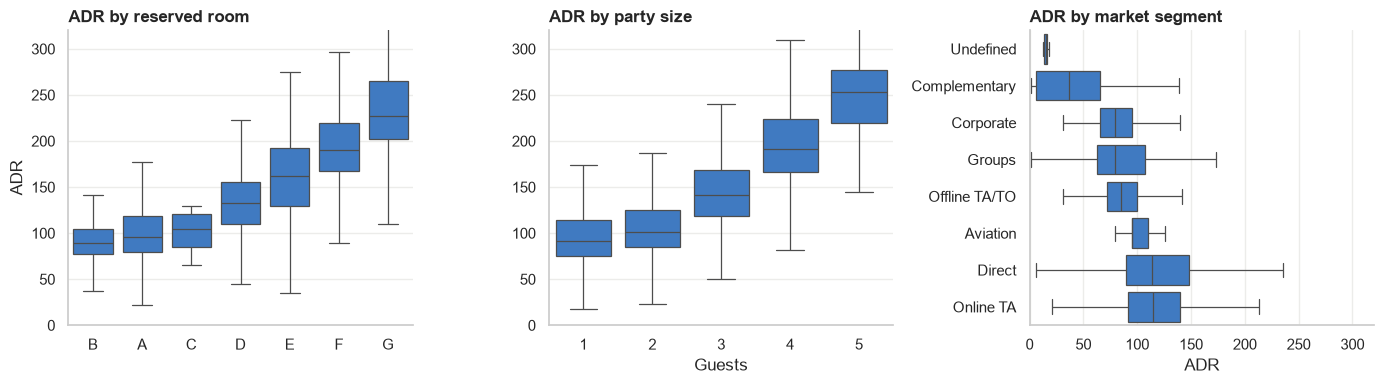

In [19]:
paid = dd[(dd.ADR > 0) & (dd.ADR <= 500) & (dd.TotalGuests > 0)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
box = dict(color=BLUE, fliersize=0, linewidth=.9)
order = paid.groupby("ReservedRoomType").ADR.median().sort_values().index
sns.boxplot(data=paid, x="ReservedRoomType", y="ADR", order=order, ax=axes[0], **box)
axes[0].set(title="ADR by reserved room", ylim=(0, 320), xlabel="")
sns.boxplot(data=paid[paid.TotalGuests <= 5], x="TotalGuests", y="ADR", ax=axes[1], **box)
axes[1].set(title="ADR by party size", ylim=(0, 320), xlabel="Guests", ylabel="")
segments = paid.groupby("MarketSegment").ADR.median().sort_values().index
sns.boxplot(data=paid, y="MarketSegment", x="ADR", order=segments, ax=axes[2], **box)
axes[2].set(title="ADR by market segment", xlim=(0, 320), ylabel="")
plt.tight_layout()

display(paid.pivot_table(index="ReservedRoomType", columns="TotalGuests", values="ADR", aggfunc="median").loc[:, 1:4].round(0))
per_guest = paid.ADR / paid.TotalGuests
print(f"Spearman: ADR vs guests {paid.ADR.corr(paid.TotalGuests, method='spearman'):.2f}, "
      f"ADR per guest vs guests {per_guest.corr(paid.TotalGuests, method='spearman'):.2f}, "
      f"ADR vs nights {paid.ADR.corr(paid.TotalNights, method='spearman'):.2f}, "
      f"ADR vs lead {paid.ADR.corr(paid.LeadTime, method='spearman'):.2f}")

**ADR drivers**

- Price is set by **room type**, then **party size**, then **season**. Room `G` has a median of around 220, room `A` around 97.
- ADR is per room. ADR per guest falls as parties grow (Spearman -0.51), so per-guest features add little and `TotalGuests` should be kept directly.
- Nights and lead time have no monotonic relationship with ADR (Spearman near 0). Any effect they have is non-linear, so trees will likely beat a plain linear baseline.

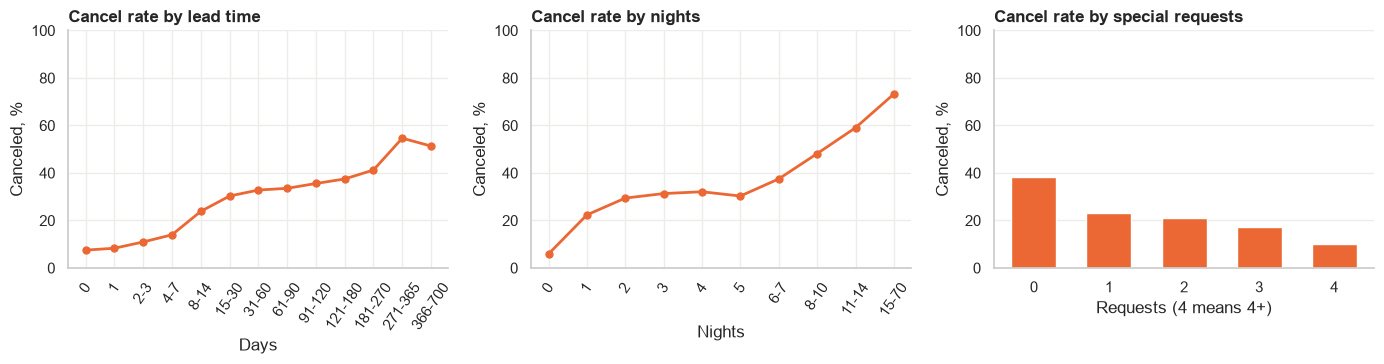

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, edges, title in [
    (axes[0], "LeadTime", [-1, 0, 1, 3, 7, 14, 30, 60, 90, 120, 180, 270, 365, 700], "Cancel rate by lead time"),
    (axes[1], "TotalNights", [-1, 0, 1, 2, 3, 4, 5, 7, 10, 14, 70], "Cancel rate by nights"),
]:
    t = dd.groupby(pd.cut(dd[col], edges), observed=True).IsCanceled.mean() * 100
    names = [f"{int(i.right)}" if i.right - i.left == 1 else f"{int(i.left) + 1}-{int(i.right)}" for i in t.index]
    ax.plot(names, t, color=ORANGE, linewidth=2, marker="o", markersize=5)
    ax.set(title=title, xlabel="Days" if col == "LeadTime" else "Nights", ylabel="Canceled, %", ylim=(0, 100))
    ax.tick_params(axis="x", rotation=55)
t = dd.groupby(dd.TotalOfSpecialRequests.clip(upper=4)).IsCanceled.mean() * 100
axes[2].bar(t.index.astype(str), t, color=ORANGE, width=.6)
axes[2].set(title="Cancel rate by special requests", xlabel="Requests (4 means 4+)", ylabel="Canceled, %", ylim=(0, 100))
axes[2].grid(axis="x", visible=False)
plt.tight_layout()

**Cancellation drivers**

- Cancel risk climbs almost continuously with lead time, from under 10% for same-day bookings to over 50% beyond nine months.
- Nights have a threshold shape: low for zero-night stays, flat from 2 to 5 nights, then rising sharply for stays above a week. A binned or tree-based representation fits this better than a linear term.
- More special requests go with fewer cancellations, but this field is mutable (section 11).

## 9. Time patterns

ADR growth 2016 to 2017 on shared months: 13.4%
Months with data per year: {2015: 6, 2016: 12, 2017: 8}


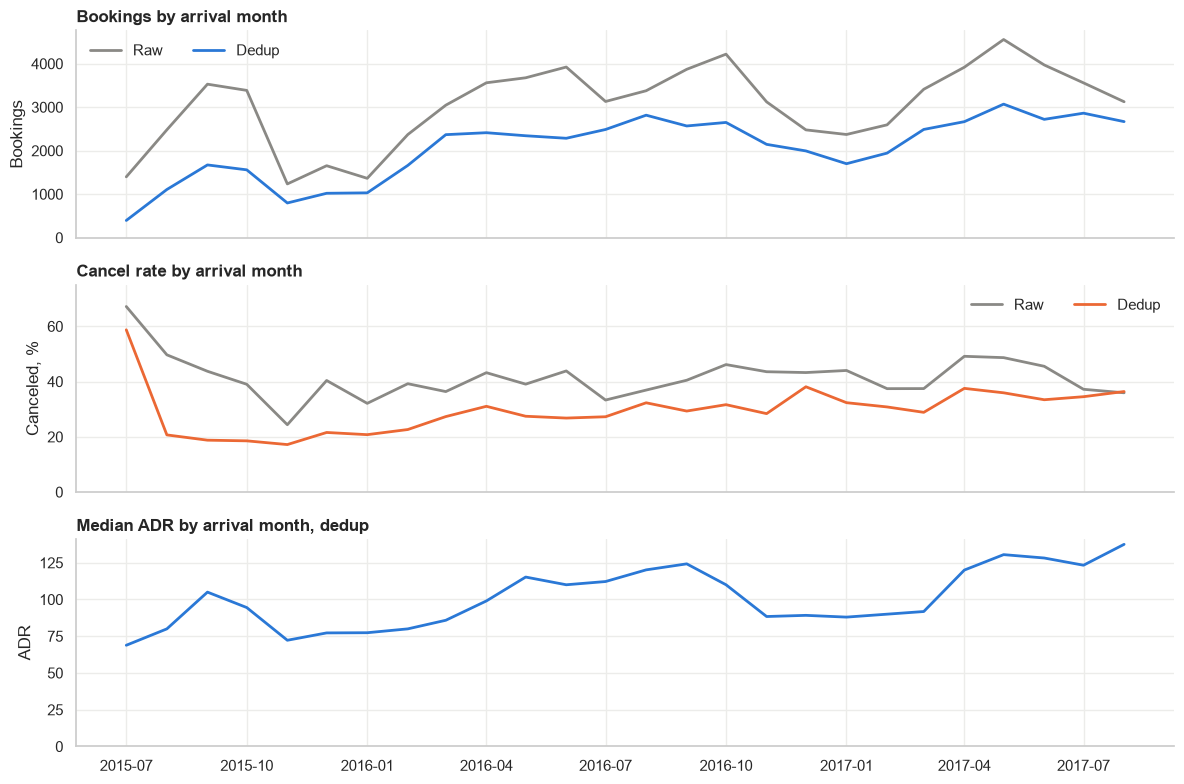

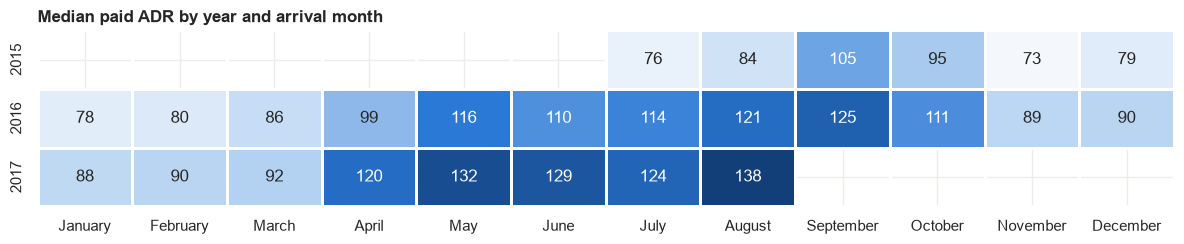

In [21]:
def monthly(frame):
    return frame.groupby(frame.ArrivalDate.dt.to_period("M").dt.to_timestamp()).agg(
        bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), adr=("ADR", "median"))


m_raw, m_dd = monthly(df), monthly(dd)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(m_raw.index, m_raw.bookings, color=GRAY, linewidth=2, label="Raw")
axes[0].plot(m_dd.index, m_dd.bookings, color=BLUE, linewidth=2, label="Dedup")
axes[0].set(title="Bookings by arrival month", ylabel="Bookings", ylim=(0, None))
axes[0].legend(frameon=False, ncols=2)
axes[1].plot(m_raw.index, m_raw.cancel * 100, color=GRAY, linewidth=2, label="Raw")
axes[1].plot(m_dd.index, m_dd.cancel * 100, color=ORANGE, linewidth=2, label="Dedup")
axes[1].set(title="Cancel rate by arrival month", ylabel="Canceled, %", ylim=(0, 75))
axes[1].legend(frameon=False, ncols=2)
axes[2].plot(m_dd.index, m_dd.adr, color=BLUE, linewidth=2)
axes[2].set(title="Median ADR by arrival month, dedup", ylabel="ADR", ylim=(0, None))
plt.tight_layout()

season = dd[dd.ADR.between(.01, 500)].pivot_table(index="ArrivalDateYear", columns="ArrivalDateMonth", values="ADR", aggfunc="median").reindex(columns=MONTHS)
fig, ax = plt.subplots(figsize=(12, 2.6))
sns.heatmap(season, cmap=SEQ, annot=True, fmt=".0f", linewidths=2, linecolor="white", cbar=False, ax=ax)
ax.set(title="Median paid ADR by year and arrival month", xlabel="", ylabel="")
plt.tight_layout()
overlap = season.loc[2016:2017].T.dropna()
print(f"ADR growth 2016 to 2017 on shared months: {(overlap[2017] / overlap[2016] - 1).mean():.1%}")
print("Months with data per year:", season.notna().sum(axis=1).to_dict())

In [22]:
display(dd.assign(Day=dd.ArrivalDate.dt.day_name()).groupby("Day").agg(
    bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), median_adr=("ADR", "median")).reindex(WEEKDAYS).T)
display(dd.groupby("ArrivalDateMonth").agg(
    bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), median_adr=("ADR", "median"), median_lead=("LeadTime", "median")).reindex(MONTHS).T)

Day,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
bookings,"8,667.000","6,679.000","7,120.000","7,959.000","8,511.000","7,357.000","7,135.000"
cancel,0.285,0.271,0.288,0.322,0.328,0.325,0.278
median_adr,105.300,103.090,103.300,107.000,106.000,107.500,104.400


ArrivalDateMonth,January,February,March,April,May,June,July,August,September,October,November,December
bookings,"2,730.000","3,605.000","4,856.000","5,080.000","5,413.000","5,005.000","5,744.000","6,591.000","4,240.000","4,208.000","2,942.000","3,014.000"
cancel,0.280,0.270,0.281,0.344,0.323,0.304,0.330,0.320,0.252,0.268,0.254,0.325
median_adr,81.000,85.000,89.000,110.670,126.000,120.000,115.600,121.500,116.100,105.300,85.000,88.000
median_lead,19.000,19.000,42.000,68.000,68.000,65.000,111.000,96.000,35.000,40.000,39.000,35.000


**What this shows**

- The data covers 26 months and the years are incomplete: 6 months of 2015, 12 of 2016, 8 of 2017. Yearly totals are not comparable, and `August` appears three times.
- Strong seasonality: ADR peaks from May to September, and median lead time peaks in July and August.
- Median ADR grew 13.4% from 2016 to 2017. A random split hides this drift, while a chronological split exposes it.
- Weekday differences are small.
- July 2015, the first month, cancels at about 60% even after dedup. It is the left edge of the data and overlaps the bulk events below, so do not read it as a seasonal effect.

### Bulk cancellations

Cancellation dates: 832. Median per day 25. Top 10 days hold 18.1% of cancellations.


,canceled,non_refund,portugal,top_segment,arrival_dates
StatusDate,,,,,
2015-10-21,1365,0.994,1.000,Groups,59
2015-01-01,760,0.711,1.000,Groups,41
2015-07-06,759,0.474,1.000,Offline TA/TO,17
2016-11-25,707,0.921,0.970,Groups,43
2016-01-18,532,0.923,0.865,Offline TA/TO,35
2015-07-02,453,0.993,1.000,Groups,18
2015-12-18,391,0.985,0.997,Offline TA/TO,14
2016-12-07,348,0.928,0.943,Groups,26


Non Refund rows 12,868: canceled 99.8%, Portugal 98.9%, no special request 99.8%, median lead 188, in an identical block 98.4%


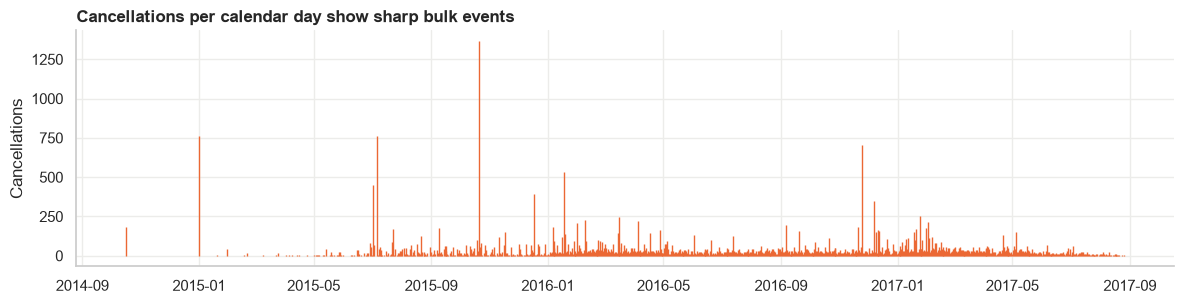

In [23]:
canceled = df[df.ReservationStatus == "Canceled"]
daily = canceled.groupby("StatusDate").size().sort_values(ascending=False)
print(f"Cancellation dates: {len(daily)}. Median per day {daily.median():.0f}. Top 10 days hold {daily.head(10).sum() / len(canceled):.1%} of cancellations.")
display(canceled[canceled.StatusDate.isin(daily.head(8).index)].groupby("StatusDate").agg(
    canceled=("ADR", "size"), non_refund=("DepositType", lambda s: (s == "Non Refund").mean()),
    portugal=("Country", lambda s: (s == "PRT").mean()), top_segment=("MarketSegment", lambda s: s.mode()[0]),
    arrival_dates=("ArrivalDate", "nunique"),
).sort_values("canceled", ascending=False))

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.vlines(daily.index, 0, daily.values, color=ORANGE, linewidth=1)
ax.set(title="Cancellations per calendar day show sharp bulk events", ylabel="Cancellations")
plt.tight_layout()

nonref = df[df.DepositType == "Non Refund"]
print(f"Non Refund rows {len(nonref):,}: canceled {nonref.IsCanceled.mean():.1%}, Portugal {(nonref.Country == 'PRT').mean():.1%}, "
      f"no special request {(nonref.TotalOfSpecialRequests == 0).mean():.1%}, median lead {nonref.LeadTime.median():.0f}, "
      f"in an identical block {dup_any[nonref.index].mean():.1%}")

**What this shows**

- Cancellations are not evenly spread. Top 10 days hold 18.1% of all cancellations, and the biggest single day canceled 1,365 bookings across 59 arrival dates.
- Those days are almost entirely Portuguese, `Non Refund`, and group or offline-agency bookings.
- `Non Refund` rows are 98.9% Portugal, 99.8% without special requests, and 98.4% in identical blocks. They look like blocks canceled by an operator, not individual customers giving up a deposit.

**Consequence:** After dedup, `DepositType` matters far less (section 11). Still, avoid explaining this result as "customers who pay upfront cancel more".

### Guest history

In [24]:
display(df.groupby("ArrivalDateYear")[["PreviousCancellations", "PreviousBookingsNotCanceled", "IsRepeatedGuest"]].mean())
display(dd.groupby(dd.PreviousCancellations.clip(upper=3)).agg(
    bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), arrived_2015=("ArrivalDateYear", lambda s: (s == 2015).mean())
).rename_axis("PreviousCancellations (3 means 3+)"))
display(dd.groupby("IsRepeatedGuest").agg(bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), median_adr=("ADR", "median"), median_lead=("LeadTime", "median")))

,PreviousCancellations,PreviousBookingsNotCanceled,IsRepeatedGuest
ArrivalDateYear,,,
2015,0.275,0.028,0.037
2016,0.058,0.155,0.024
2017,0.013,0.153,0.022


,bookings,cancel,arrived_2015
PreviousCancellations (3 means 3+),,,
0,52250,0.292,0.113
1,966,0.803,0.651
2,72,0.181,0.208
3,140,0.136,0.014


,bookings,cancel,median_adr,median_lead
IsRepeatedGuest,,,,
0,51720,0.307,106.675,54.000
1,1708,0.111,66.000,3.000


**What this shows**

- `PreviousCancellations` averages 0.275 in 2015 and 0.013 in 2017, while `PreviousBookingsNotCanceled` moves the other way. The meaning of these columns changes over the dataset.
- The value 1 has an 80.3% cancel rate, but 2 or more have far lower rates. 65.1% of the value-1 rows arrived in 2015. This looks like an artifact of bulk profiles, not a rule that one past cancellation predicts another.
- The paper counts bookings "created before" the current one and canceled, without saying the cancellation also came first. An earlier booking canceled later would be future information. This is a subtle indirect leak risk.
- Repeat guests are 3.2% of rows, book late, pay less, and rarely cancel.

## 10. Relationships between features

,,spearman
IsRepeatedGuest,PreviousBookingsNotCanceled,0.857
Adults,TotalGuests,0.856
StaysInWeekNights,TotalNights,0.839
StaysInWeekendNights,TotalNights,0.584
Children,TotalGuests,0.512
ArrivalDateYear,ArrivalDateWeekNumber,-0.509
ADR,TotalGuests,0.426
Adults,ADR,0.340
IsRepeatedGuest,PreviousCancellations,0.331
LeadTime,TotalNights,0.330


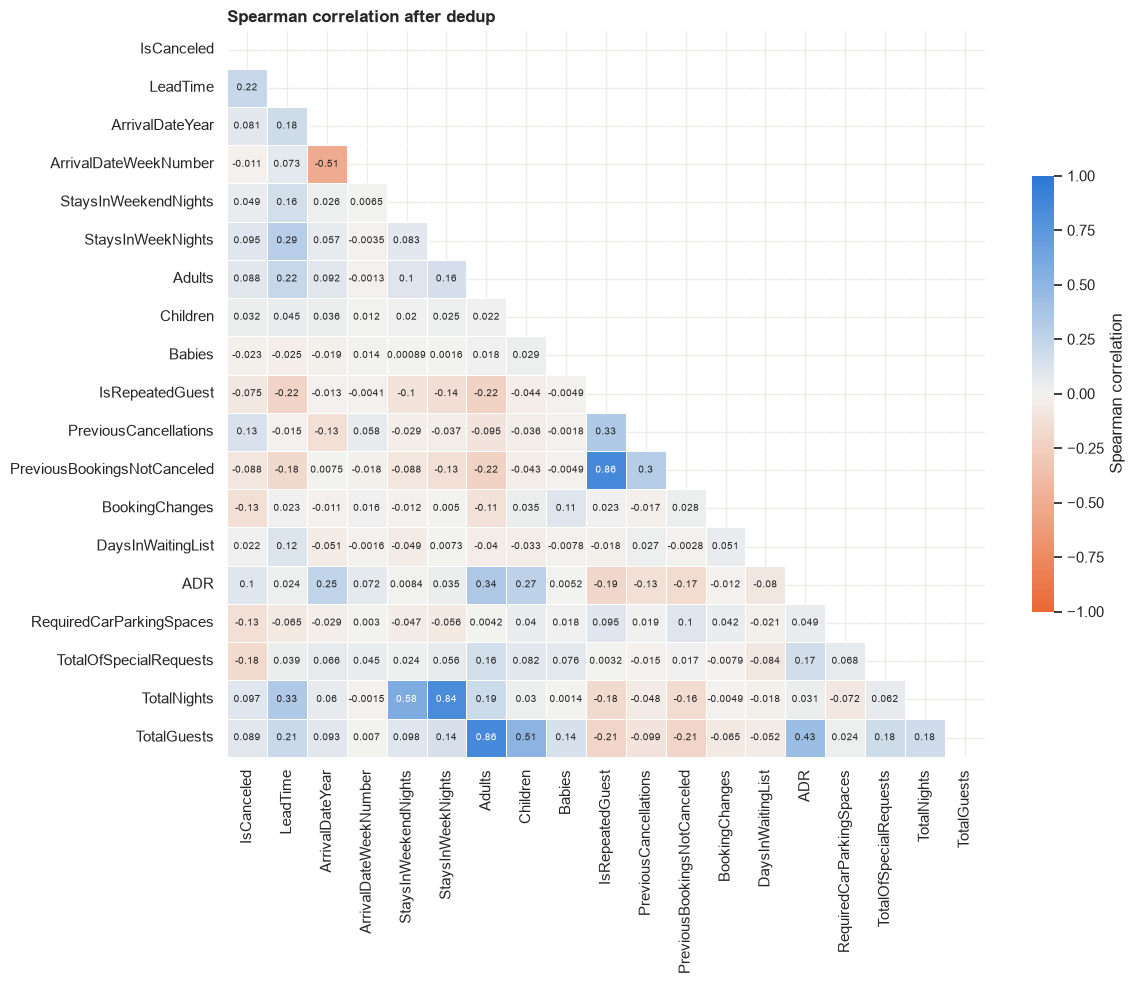

In [37]:
assoc = [c for c in NUMERIC if c != "ArrivalDateDayOfMonth"] + ["TotalNights", "TotalGuests"]
corr = dd[assoc].corr(method="spearman")
upper = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap=DIV, center=0, vmin=-1, vmax=1, annot=True, annot_kws={"size": 7}, linewidths=.5, linecolor="white",
            mask=upper, cbar_kws={"shrink": .6, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlation after dedup")
plt.tight_layout()
corr.where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack().sort_values(key=np.abs, ascending=False).head(12).to_frame("spearman")

DistributionChannel,Corporate,Direct,GDS,TA/TO,Undefined
MarketSegment,,,,,
Aviation,95.600,0.000,0.000,4.400,0.000
Complementary,12.300,80.700,0.000,7.000,0.000
Corporate,92.400,2.300,0.000,5.300,0.000
Direct,0.100,99.200,0.000,0.700,0.000
Groups,6.000,1.800,0.000,92.200,0.000
Offline TA/TO,1.100,0.100,0.600,98.200,0.000
Online TA,0.100,0.200,0.400,99.400,0.000
Undefined,0.000,0.000,0.000,0.000,100.000


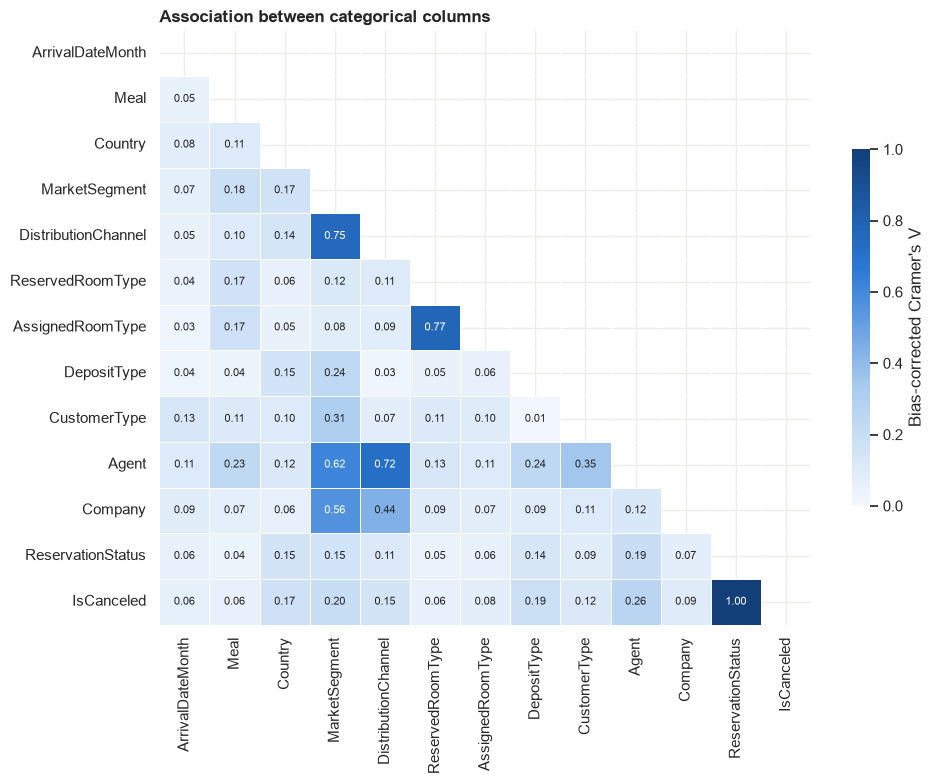

In [26]:
def cramers_v(a, b):
    table = pd.crosstab(a, b).to_numpy()
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.sum()
    rows, cols = table.shape
    phi2 = max(0, chi2 / n - (rows - 1) * (cols - 1) / (n - 1))
    r, k = rows - (rows - 1) ** 2 / (n - 1), cols - (cols - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(r, k) - 1, 1e-9))


def top_levels(s, k=30):
    return s.where(s.isin(s.value_counts().index[:k]), "Other")


v_cols = CATS + ["ReservationStatus", "IsCanceled"]
tmp = dd[v_cols].astype(str).apply(top_levels)
v = pd.DataFrame(np.eye(len(v_cols)), index=v_cols, columns=v_cols)
for i, a in enumerate(v_cols):
    for b in v_cols[i + 1:]:
        v.loc[a, b] = v.loc[b, a] = cramers_v(tmp[a], tmp[b])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(v, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=.5, linecolor="white",
            mask=np.triu(np.ones_like(v, dtype=bool)), cbar_kws={"shrink": .6, "label": "Bias-corrected Cramer's V"}, ax=ax)
ax.set_title("Association between categorical columns")
plt.tight_layout()
(pd.crosstab(dd.MarketSegment, dd.DistributionChannel, normalize="index") * 100).round(1)

**What this shows**

- Redundancy is structural: `TotalNights` and `TotalGuests` are sums of their parts, `IsRepeatedGuest` tracks history.
- `MarketSegment` and `DistributionChannel` overlap heavily. `Online TA` is 99.4% `TA/TO`, `Direct` 99.2% `Direct`. Keep `MarketSegment`, drop `DistributionChannel` for linear models or LDA.
- `ReservedRoomType` and `AssignedRoomType` overlap strongly (Cramer's V 0.77), so `AssignedRoomType` adds little for pricing while carrying timing risk.

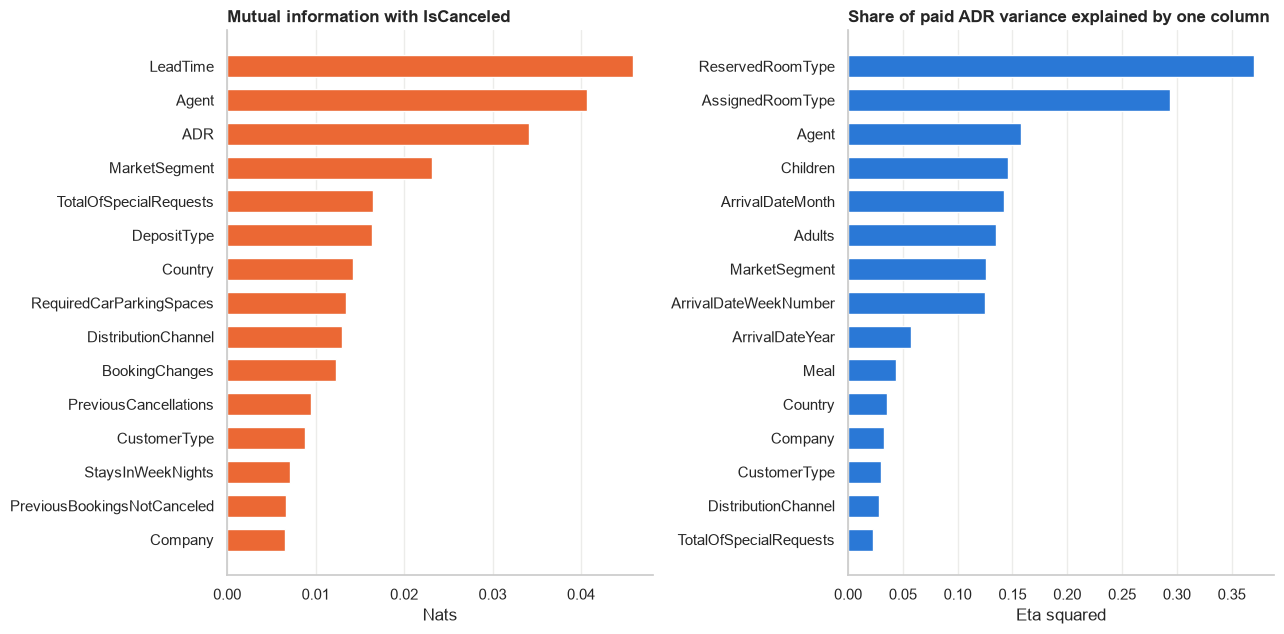

In [27]:
cand = [c for c in raw.columns if c not in {"IsCanceled", "ReservationStatus", "ReservationStatusDate"}]
sample = dd.sample(20000, random_state=SEED)
X = sample[cand].copy()
for c in cand:
    if not pd.api.types.is_numeric_dtype(X[c]):
        X[c] = top_levels(X[c].astype(str)).astype("category").cat.codes
X = X.fillna(0)
mi = pd.Series(mutual_info_classif(X, sample.IsCanceled, discrete_features=[c != "ADR" for c in cand], random_state=SEED), index=cand)


def eta_squared(frame, feature, target="ADR"):
    grouped = frame.groupby(feature, observed=True)[target]
    mean = frame[target].mean()
    return (grouped.size() * (grouped.mean() - mean) ** 2).sum() / ((frame[target] - mean) ** 2).sum()


paid = dd[dd.ADR.between(.01, 500)]
eta = pd.Series({c: eta_squared(paid.assign(**{c: top_levels(paid[c].astype(str))}), c) for c in cand if c != "ADR"})

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
a = mi.sort_values().tail(15)
axes[0].barh(a.index, a, color=ORANGE, height=.65)
axes[0].set(title="Mutual information with IsCanceled", xlabel="Nats")
b = eta.sort_values().tail(15)
axes[1].barh(b.index, b, color=BLUE, height=.65)
axes[1].set(title="Share of paid ADR variance explained by one column", xlabel="Eta squared")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()

In [28]:
vif_cols = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children", "Babies", "ADR",
            "PreviousCancellations", "PreviousBookingsNotCanceled", "IsRepeatedGuest", "TotalOfSpecialRequests",
            "ArrivalDateWeekNumber", "ArrivalDateYear"]
frame = dd[vif_cols].fillna(0).astype(float)
display(pd.Series(np.diag(np.linalg.pinv(frame.corr().to_numpy())), index=vif_cols, name="VIF").sort_values(ascending=False).to_frame().T)
scale = dd[vif_cols].std().sort_values(ascending=False)
print(f"Standard deviations span {scale.iloc[0]:.1f} ({scale.index[0]}) to {scale.iloc[-1]:.3f} ({scale.index[-1]}), a factor of {scale.iloc[0] / scale.iloc[-1]:.0f}.")

,ArrivalDateYear,PreviousBookingsNotCanceled,ArrivalDateWeekNumber,IsRepeatedGuest,ADR,PreviousCancellations,Adults,LeadTime,StaysInWeekNights,Children,StaysInWeekendNights,TotalOfSpecialRequests,Babies
VIF,1.632,1.606,1.502,1.433,1.399,1.365,1.210,1.179,1.139,1.139,1.113,1.050,1.006


Standard deviations span 82.1 (LeadTime) to 0.103 (Babies), a factor of 800.


**What this shows**

- No raw numeric feature has a worrying VIF (all under 2). Adding sums such as `TotalNights` alongside their parts would create exact collinearity, so use one form per model.
- Scales differ by a factor of about 800, so distance-based models, SVM, MLP and PCA need scaling.
- Univariate rankings are only a guide, because mutable fields score high for the wrong reasons. The next section tests them.

## 11. Leakage and validation probes

These quick gradient-boosting probes measure the effect of each choice, not final model quality. They train on arrivals before 2017-03-06, validate up to 2017-06-03, and never touch the latest 15%. They are untuned.

The baseline uses fields available at booking. Each other feature is then added on its own.

In [29]:
probe = dd.sort_values("ArrivalDate").copy()
FINAL_CUT = probe.ArrivalDate.quantile(.85)
TRAIN_CUT = probe.ArrivalDate.quantile(.70)
tr = probe[probe.ArrivalDate < TRAIN_CUT]
va = probe[(probe.ArrivalDate >= TRAIN_CUT) & (probe.ArrivalDate < FINAL_CUT)]
print(f"Train {len(tr):,} rows before {TRAIN_CUT.date()} | Validation {len(va):,} rows before {FINAL_CUT.date()} | "
      f"Left unused {(probe.ArrivalDate >= FINAL_CUT).sum():,} rows")


def encoded(train, valid, cols):
    a, b = train[cols].copy(), valid[cols].copy()
    for c in cols:
        if c in CATS:
            levels = a[c].value_counts().index[:60]
            a[c] = pd.Categorical(a[c].where(a[c].isin(levels), "Other"), categories=[*levels, "Other"])
            b[c] = pd.Categorical(b[c].where(b[c].isin(levels), "Other"), categories=[*levels, "Other"])
    return a, b


def auc_of(cols, train=None, valid=None):
    train, valid = (tr, va) if train is None else (train, valid)
    a, b = encoded(train, valid, cols)
    model = HistGradientBoostingClassifier(max_iter=150, categorical_features="from_dtype", random_state=SEED)
    return roc_auc_score(valid.IsCanceled, model.fit(a, train.IsCanceled).predict_proba(b)[:, 1])


def fit_adr(cols, train=None, valid=None):
    train, valid = (tr_reg, va_reg) if train is None else (train, valid)
    a, b = encoded(train, valid, cols)
    model = HistGradientBoostingRegressor(max_iter=150, categorical_features="from_dtype", random_state=SEED)
    pred = model.fit(a, train.ADR).predict(b)
    return {"MAE": mean_absolute_error(valid.ADR, pred), "R2": r2_score(valid.ADR, pred)}


AT_BOOKING = ["LeadTime", "ArrivalDateMonth", "ArrivalDateDayOfMonth", "StaysInWeekendNights", "StaysInWeekNights", "Adults",
              "Children", "Babies", "Meal", "MarketSegment", "DistributionChannel", "ReservedRoomType", "CustomerType"]
base_cls = AT_BOOKING + ["ADR", "DepositType", "IsRepeatedGuest", "PreviousBookingsNotCanceled", "PreviousCancellations"]
base_auc = auc_of(base_cls)
tests = ["DaysInWaitingList", "TotalOfSpecialRequests", "Agent", "Company", "Country", "BookingChanges", "RequiredCarParkingSpaces", "AssignedRoomType"]
cls_probe = pd.DataFrame({"AUC_with_feature": {f: auc_of(base_cls + [f]) for f in tests}})
cls_probe["gain"] = cls_probe.AUC_with_feature - base_auc
drops = pd.DataFrame({"AUC_without_feature": {f: auc_of([c for c in base_cls if c != f]) for f in ["DepositType", "ADR", "PreviousCancellations"]}})
drops["change"] = drops.AUC_without_feature - base_auc
print(f"Baseline AUC with at-booking fields: {base_auc:.3f}")
display(cls_probe.sort_values("gain", ascending=False), drops)

Train 37,365 rows before 2017-03-06 | Validation 8,019 rows before 2017-06-03 | Left unused 8,044 rows
Baseline AUC with at-booking fields: 0.724


,AUC_with_feature,gain
Country,0.770,0.045
TotalOfSpecialRequests,0.748,0.024
Agent,0.746,0.022
RequiredCarParkingSpaces,0.738,0.013
AssignedRoomType,0.732,0.007
BookingChanges,0.731,0.007
DaysInWaitingList,0.727,0.003
Company,0.727,0.003


,AUC_without_feature,change
DepositType,0.718,-0.006
ADR,0.709,-0.015
PreviousCancellations,0.727,0.002


In [30]:
moved = (dd.ReservedRoomType != dd.AssignedRoomType).rename("RoomChanged")
display(dd.groupby(moved).agg(bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), median_adr=("ADR", "median")))
display(dd.groupby(dd.RequiredCarParkingSpaces.clip(upper=1).rename("WantsParking")).agg(bookings=("ADR", "size"), cancel=("IsCanceled", "mean")))
display(dd.groupby(dd.BookingChanges.clip(upper=3).rename("BookingChanges (3 means 3+)")).agg(bookings=("ADR", "size"), cancel=("IsCanceled", "mean"), median_adr=("ADR", "median")))
c = dd[dd.ReservationStatus == "Canceled"]
print(f"Cancellation timing: median {(c.ArrivalDate - c.StatusDate).dt.days.median():.0f} days before arrival; "
      f"{(c.StatusDate == c.BookingDate).mean():.1%} on the booking day; "
      f"{((c.StatusDate - c.BookingDate).dt.days <= 7).mean():.1%} within 7 days of booking.")

,bookings,cancel,median_adr
RoomChanged,,,
False,47336,0.332,106.250
True,6092,0.052,96.900


,bookings,cancel
WantsParking,,
0,51532,0.311
1,1896,0.000


,bookings,cancel,median_adr
BookingChanges (3 means 3+),,,
0,44584,0.327,105.400
1,6023,0.135,101.000
2,2068,0.236,108.000
3,753,0.195,109.650


Cancellation timing: median 36 days before arrival; 14.2% on the booking day; 42.2% within 7 days of booking.


**How to read this**

A small AUC gain does not prove a feature is safe, and a large one does not prove leakage. Timing decides. The probe shows how much is at stake.

- `Country` gives the biggest gain (+0.045), and its timing is unverified. Keep it out of the primary cancellation model and report it as a sensitivity check.
- `RequiredCarParkingSpaces`: a perfect 0% cancel rate on 1,896 rows is implausible as pure customer behavior. Exclude it.
- `AssignedRoomType`: mostly set near arrival. A moved booking has nearly reached check-in, so its 5.2% cancel rate reflects survival. Exclude it.
- `BookingChanges`: counted until check-in or cancellation, so a booking that survives longer has more chances to change. Exclude it.
- `TotalOfSpecialRequests`: can accumulate after booking. Exclude it from the primary model, or use it only if the team defines a later prediction point.
- `ReservationStatus`, `ReservationStatusDate`: restate the target. Always exclude.
- `DepositType`: dropping it costs only 0.006 AUC after dedup, so the extreme raw signal was mostly duplicates.
- Timing matters for prediction too: 42.2% of cancellations happen within 7 days of booking, so a day-before-arrival prediction point would answer a different, easier question.

### ADR probe

In [31]:
tr_reg = tr[tr.ADR.between(.01, 500)]
va_reg = va[va.ADR.between(.01, 500)]
base_reg = AT_BOOKING + ["DepositType", "IsRepeatedGuest", "PreviousBookingsNotCanceled", "PreviousCancellations"]
rows = {"baseline": fit_adr(base_reg)}
for f in ["Country", "Agent", "Company", "TotalOfSpecialRequests", "RequiredCarParkingSpaces", "BookingChanges", "IsCanceled", "AssignedRoomType", "ArrivalDateYear"]:
    rows[f"+ {f}"] = fit_adr(base_reg + [f])
reg_probe = pd.DataFrame(rows).T
reg_probe["MAE_change"] = reg_probe.MAE - reg_probe.loc["baseline", "MAE"]
reg_probe

,MAE,R2,MAE_change
baseline,22.185,0.506,0.000
+ Country,21.767,0.522,-0.418
+ Agent,19.801,0.585,-2.384
+ Company,22.017,0.509,-0.169
+ TotalOfSpecialRequests,22.146,0.510,-0.039
+ RequiredCarParkingSpaces,22.246,0.508,0.061
+ BookingChanges,22.161,0.510,-0.025
+ IsCanceled,22.252,0.504,0.066
+ AssignedRoomType,22.257,0.508,0.072
+ ArrivalDateYear,20.788,0.556,-1.398


**How to read this**

- `Agent` is the most useful addition (MAE -2.4), and is known at booking. This is a strong reason to reverse its removal.
- `ArrivalDateYear` also helps (MAE -1.4), since it carries price drift. Trees cannot extrapolate beyond training years, so expect some bias on newer data.
- `IsCanceled`, `AssignedRoomType`, parking and `BookingChanges` add nothing here. Exclude them anyway: they are unknown when a price is quoted.

### Split strategy

In [32]:
safe = base_cls + ["DaysInWaitingList", "Agent", "Company"]
dev_raw, dev_dd = df[df.ArrivalDate < FINAL_CUT], dd[dd.ArrivalDate < FINAL_CUT]
key = list(raw.columns)
results = {}
for name, data in [("Raw rows, random split", dev_raw), ("Dedup rows, random split", dev_dd)]:
    a, b = train_test_split(data, test_size=.25, random_state=SEED, stratify=data.IsCanceled)
    twins = b[key].merge(a[key].drop_duplicates(), how="left", on=key, indicator=True)["_merge"].eq("both").mean()
    results[name] = {"AUC": auc_of(safe, a, b), "validation_rows_with_twin_in_train": twins}
results["Dedup rows, chronological split"] = {"AUC": auc_of(safe), "validation_rows_with_twin_in_train": 0.0}
display(pd.DataFrame(results).T)

dev_paid = dev_dd[dev_dd.ADR.between(.01, 500)]
a, b = train_test_split(dev_paid, test_size=.25, random_state=SEED)
display(pd.DataFrame({"Random split": fit_adr(base_reg, a, b), "Chronological split": fit_adr(base_reg)}).T)

,AUC,validation_rows_with_twin_in_train
"Raw rows, random split",0.901,0.391
"Dedup rows, random split",0.791,0.000
"Dedup rows, chronological split",0.747,0.000


,MAE,R2
Random split,13.228,0.742
Chronological split,22.185,0.506


In [33]:
def psi(train, valid, bins=10):
    edges = np.unique(train.quantile(np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p = np.histogram(train, edges)[0] / len(train) + 1e-4
    q = np.histogram(valid, edges)[0] / len(valid) + 1e-4
    return ((q - p) * np.log(q / p)).sum()


def psi_cat(train, valid):
    index = pd.Index(train.unique()).union(valid.unique())
    p = train.value_counts(normalize=True).reindex(index, fill_value=0) + 1e-4
    q = valid.value_counts(normalize=True).reindex(index, fill_value=0) + 1e-4
    return ((q - p) * np.log(q / p)).sum()


shift = {c: psi(tr[c].dropna(), va[c].dropna()) for c in ["LeadTime", "ADR", "TotalNights", "PreviousCancellations", "TotalOfSpecialRequests"]}
shift |= {c: psi_cat(tr[c], va[c]) for c in ["Country", "MarketSegment", "Agent", "Company", "DepositType", "CustomerType", "ReservedRoomType", "Meal"]}
display(pd.Series(shift, name="PSI, train vs validation period").sort_values(ascending=False).to_frame().T)
print("Validation rows with a category never seen in train, %:", {c: round((~va[c].isin(tr[c])).mean() * 100, 2) for c in ["Country", "Agent", "Company"]})

,Agent,ADR,CustomerType,Country,LeadTime,Company,ReservedRoomType,MarketSegment,TotalNights,Meal,TotalOfSpecialRequests,DepositType,PreviousCancellations
"PSI, train vs validation period",0.337,0.321,0.157,0.151,0.139,0.102,0.050,0.037,0.035,0.029,0.006,0.001,0.000


Validation rows with a category never seen in train, %: {'Country': np.float64(0.06), 'Agent': np.float64(2.26), 'Company': np.float64(1.06)}


**What this shows**

- On raw rows, 39.1% of validation rows have an identical twin in training, and AUC reaches 0.901. That number is mostly memorization.
- Dedup lowers AUC to 0.791, and a chronological split lowers it to 0.747. The honest estimate is the lowest one. These three runs use different validation rows, so compare them as an order of magnitude, not an exact penalty.
- ADR error rises from 13.2 to 22.2 MAE when validation moves forward in time. Drift is the largest single issue for regression.
- PSI shows strong shift for `Agent` and `ADR`, and moderate shift for `CustomerType`, `Country` and `LeadTime`. 2.3% of validation rows have an `Agent` never seen in training, so encoders must accept unknown categories.

**Recommended split:** sort by arrival date, keep the latest 15% as the final test set, and use forward-chaining folds on the rest. This test window covers only summer arrivals, so it should be reported alongside the season-limited scope.

## 12. Clustering readiness

,LeadTime,TotalNights,TotalGuests,Children,TotalOfSpecialRequests,IsRepeatedGuest,ADR
PC1,0.360,0.330,0.540,0.400,0.170,-0.340,0.410
PC2,-0.440,-0.460,0.380,0.560,0.140,0.350,-0.060
PC3,0.170,0.210,-0.030,-0.120,0.860,0.340,-0.220


Hopkins statistic: 0.997 (0.5 means no cluster tendency, near 1 means strong)
Rows sharing an exact point with another row on these fields: 8.0%


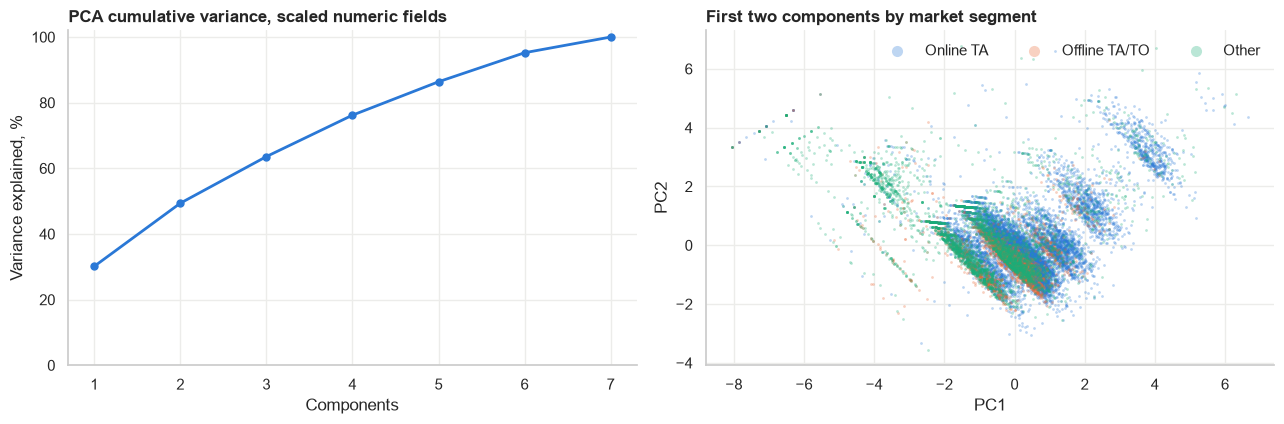

In [34]:
CLUSTER_COLS = ["LeadTime", "TotalNights", "TotalGuests", "Children", "TotalOfSpecialRequests", "IsRepeatedGuest", "ADR"]
blend = dd[dd.ADR <= 500].dropna(subset=["Children"]).sample(20000, random_state=SEED)
Z = blend[CLUSTER_COLS].astype(float).copy()
for c in ["LeadTime", "TotalNights", "ADR"]:
    Z[c] = np.log1p(Z[c])
Z = StandardScaler().fit_transform(Z)
pca = PCA(random_state=SEED).fit(Z)
Y = pca.transform(Z)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
curve = pca.explained_variance_ratio_.cumsum() * 100
axes[0].plot(range(1, len(curve) + 1), curve, color=BLUE, linewidth=2, marker="o", markersize=5)
axes[0].set(title="PCA cumulative variance, scaled numeric fields", xlabel="Components", ylabel="Variance explained, %", ylim=(0, 102))
groups = blend.MarketSegment.where(blend.MarketSegment.isin(["Online TA", "Offline TA/TO"]), "Other")
for name, color in [("Online TA", BLUE), ("Offline TA/TO", ORANGE), ("Other", AQUA)]:
    m = (groups == name).to_numpy()
    axes[1].scatter(Y[m, 0], Y[m, 1], s=4, alpha=.3, color=color, label=name, linewidths=0)
axes[1].set(title="First two components by market segment", xlabel="PC1", ylabel="PC2")
axes[1].legend(frameon=False, markerscale=4, ncols=3, loc="upper right")
plt.tight_layout()
display(pd.DataFrame(pca.components_[:3], columns=CLUSTER_COLS, index=["PC1", "PC2", "PC3"]).round(2))


def hopkins(data, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(data), n, replace=False)
    uniform = rng.uniform(data.min(0), data.max(0), size=(n, data.shape[1]))
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    w = nn.kneighbors(data[idx])[0][:, 1]
    u = nn.kneighbors(uniform, n_neighbors=1)[0][:, 0]
    return (u ** 2).sum() / ((u ** 2).sum() + (w ** 2).sum())


print(f"Hopkins statistic: {hopkins(Z):.3f} (0.5 means no cluster tendency, near 1 means strong)")
print(f"Rows sharing an exact point with another row on these fields: {1 - len(blend[CLUSTER_COLS].drop_duplicates()) / len(blend):.1%}")

**What this shows**

- Variance is spread out: PC1 explains about 30%, and it takes five of seven components to reach about 85%. Aggressive PCA would lose information.
- The stripes in the scatter come from discrete fields such as party size, not from natural segments.
- Hopkins is near 1, but do not over-read it. Discrete fields create a lattice of repeated points that inflates this statistic. Use silhouette and Davies-Bouldin from the real clustering runs.
- 8.0% of rows sit on the same point as another row, even after dedup. DBSCAN will find these dense spots, and `eps` needs care.

**Clustering leakage:** exclude `IsCanceled`, `ReservationStatus`, `ReservationStatusDate`, plus `AssignedRoomType` and `BookingChanges`. Treat `DepositType` and `PreviousCancellations` as outcome proxies and leave them out. Use dedup rows, or blocks will form false clusters.

## 13. Generic preprocessing plan

### Deterministic cleaning, safe before the split

These steps learn nothing from the data.

In [35]:
def generic_clean(frame):
    """Deterministic row and value fixes that learn nothing from the data, so they are safe before splitting."""
    out = tidy(frame.drop_duplicates())
    steps = {"after exact dedup": len(out)}
    out = out[out.TotalGuests > 0]
    steps["drop zero guests"] = len(out)
    out = out[out.ADR <= 1000]
    steps["drop ADR 5400"] = len(out)
    out = out[(out.MarketSegment != "Undefined") & (out.DistributionChannel != "Undefined")]
    steps["drop Undefined segment or channel"] = len(out)
    out["Children"] = out["Children"].fillna(0).astype(int)
    out["Country"] = out["Country"].replace("NULL", "Unknown")
    out["HasAgent"] = (out.Agent != "NULL").astype(int)
    out["HasCompany"] = (out.Company != "NULL").astype(int)
    return out, steps


clean, steps = generic_clean(raw)
display(pd.Series({"raw rows": len(raw), **steps}, name="rows").to_frame().T)
print(f"Clean: cancel rate {clean.IsCanceled.mean():.1%}, median ADR {clean.ADR.median():.1f}, ADR max {clean.ADR.max():.1f}, "
      f"ADR = 0 rows {(clean.ADR == 0).sum():,}, missing Children {clean.Children.isna().sum()}")
print(f"Regression rows with ADR > 0: {(clean.ADR > 0).sum():,}")

,raw rows,after exact dedup,drop zero guests,drop ADR 5400,drop Undefined segment or channel
rows,79330,53428,53274,53273,53269


Clean: cancel rate 30.1%, median ADR 105.3, ADR max 510.0, ADR = 0 rows 953, missing Children 0
Regression rows with ADR > 0: 52,316


### Ordered plan

| Step | Action | Reason | Where |
|---|---|---|---|
| 1 | Strip all text columns | Padding on 7 columns | Before split |
| 2 | Parse numerics and build `ArrivalDate` | Everything arrives as text | Before split |
| 3 | Dedup on all 31 columns | Prevents twin leakage. Must precede dropping columns | Before split |
| 4 | Drop zero guests, `ADR = 5400`, `Undefined` segment or channel | Invalid or too rare to learn from | Before split |
| 5 | Sort by arrival, hold out latest 15% | Matches real use and exposes drift | Split |
| 6 | Build per-task feature lists | Section 11 | After split |
| 7 | `Children` to 0, `Country` `NULL` to `Unknown` | Very few rows | Pipeline |
| 8 | `HasAgent`, `HasCompany`, top-k `Agent`, `Company`, `Country` with `Other` | NULL is meaningful. Long tails | Pipeline, fit on train |
| 9 | Group rare levels, one-hot with `handle_unknown="ignore"` | Unseen levels occur | Pipeline, fit on train |
| 10 | Flags or caps: `Babies` at 2, `HasPreviousCancel`, `IsRepeatedGuest`, `HasSpecialRequest` | Zero inflation | Pipeline |
| 11 | Cyclical month or day-of-year, plus a linear time index | Seasonality and drift | Pipeline |
| 12 | Yeo-Johnson for `LeadTime` and stays, then `StandardScaler` for scale-sensitive models only | Skew and factor 800 scale gap. `RobustScaler` is a poor fit, since IQR is 0 for most counts | Pipeline, fit on train |
| 13 | Regression: train on `ADR > 0` | Zero ADR is free or undefined | Task |

### Feature policy by task

The prediction point below is a proposal for the team to confirm: **the moment a booking is confirmed**.

| Column group | `IsCanceled` | `ADR` | Clustering |
|---|---|---|---|
| `LeadTime`, stays, party size, `Meal`, `ReservedRoomType` | Use | Use | Use |
| Arrival month and day | Use | Use | Use month only |
| `MarketSegment`, `CustomerType` | Use | Use | Use |
| `DistributionChannel` | Optional, redundant | Optional, redundant | Skip |
| `Agent`, `Company` (flags and grouped) | Use | Use | Flags only |
| `ADR` | Use, quoted rate | Target | Use |
| `DepositType` | Use, with caution | Use | Skip, outcome proxy |
| `IsRepeatedGuest`, `PreviousBookingsNotCanceled` | Use | Use | Use `IsRepeatedGuest` |
| `PreviousCancellations` | Flag only, drifts | Skip | Skip, outcome proxy |
| `DaysInWaitingList` | Use, flag | Use, flag | Skip |
| `Country` | Sensitivity run only | Use | Grouped, optional |
| `TotalOfSpecialRequests` | Exclude, mutable | Skip | Optional, describe only |
| `RequiredCarParkingSpaces` | Exclude | Exclude | Describe only |
| `BookingChanges` | Exclude | Exclude | Exclude |
| `AssignedRoomType` | Exclude | Exclude | Exclude |
| `IsCanceled` | Target | Exclude | Exclude |
| `ReservationStatus`, `ReservationStatusDate` | Exclude | Exclude | Exclude |
| Source week number, `ArrivalDateYear` | Skip year | Use year, skip week | Skip |

### Changes needed in `preprocessing.ipynb`

| Current step | Issue | Change |
|---|---|---|
| Drop `Agent` and `Company` as a leakage measure | The paper says `NULL` means not applicable, so this is not leakage. Removing them also costs 2.4 ADR MAE | Keep them, encoded as above |
| `drop_duplicates()` after dropping columns | Merges 14 distinct bookings | Dedup first, on all 31 columns |
| No whitespace stripping | 7 columns stay padded | Strip right after loading |
| `SimpleImputer(fill_value="-1")` on all numeric columns | Only `Children` has `NA`. `-1` is an impossible count and it is fitted before any split | Fill `Children` with 0 |
| Correlation heatmap with `vmin=1, vmax=1` | The color scale has no range, so it shows no information | Use `vmin=-1, vmax=1` |
| Pair grid over 18 columns on all rows | Very slow, and most columns are discrete | Replace with the targeted plots here |

### Open decisions for the team

1. Confirm the prediction point. This notebook assumes booking confirmation.
2. Confirm dedup as the main population, and describe its consequences in the report.
3. Decide whether `Country` stays out of the cancellation model. The evidence supports excluding it, but cannot prove leakage.